STEP 1 — Set up the paths

In [1]:
import os
import pandas as pd
import pdfplumber

csv_path = "../data/raw/Global_Landslide_Catalog_Export_rows.csv"
pdf_path = "../data/raw/landslide_report_compressed.pdf"

print("CSV exists:", os.path.exists(csv_path))
print("PDF exists:", os.path.exists(pdf_path))

CSV exists: True
PDF exists: True


STEP 2 — Load the CSV

In [2]:
df_csv = pd.read_csv(csv_path)

print("Dataset shape:", df_csv.shape)

display(df_csv.head())

Dataset shape: (11033, 31)


,source_name,source_link,event_id,event_date,event_time,event_title,event_description,location_description,location_accuracy,landslide_category,...,country_code,admin_division_name,admin_division_population,gazeteer_closest_point,gazeteer_distance,submitted_date,created_date,last_edited_date,longitude,latitude
0,AGU,https://blogs.agu.org/landslideblog/2008/10/14...,684,08/01/2008 12:00:00 AM,NaN,"Sigou Village, Loufan County, Shanxi Province","occurred early in morning, 11 villagers buried...","Sigou Village, Loufan County, Shanxi Province",unknown,landslide,...,CN,Shaanxi,0.0,Jingyang,41.02145,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,107.4500,32.5625
1,Oregonian,http://www.oregonlive.com/news/index.ssf/2009/...,956,01/02/2009 02:00:00 AM,NaN,"Lake Oswego, Oregon",Hours of heavy rain are to blame for an overni...,"Lake Oswego, Oregon",5km,mudslide,...,US,Oregon,36619.0,Lake Oswego,0.60342,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,-122.6630,45.4200
2,CBS News,https://www.cbsnews.com/news/dozens-missing-af...,973,01/19/2007 12:00:00 AM,NaN,"San Ramon district, 195 miles northeast of the...",(CBS/AP) At least 10 people died and as many a...,"San Ramon district, 195 miles northeast of the...",10km,landslide,...,PE,Junín,14708.0,San Ramón,0.85548,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,-75.3587,-11.1295
3,Reuters,https://in.reuters.com/article/idINIndia-41450...,1067,07/31/2009 12:00:00 AM,NaN,Dailekh district,"One person was killed in Dailekh district, pol...",Dailekh district,unknown,landslide,...,NP,Mid Western,20908.0,Dailekh,0.75395,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,81.7080,28.8378
4,The Freeman,http://www.philstar.com/cebu-news/621414/lands...,2603,10/16/2010 12:00:00 PM,NaN,sitio Bakilid in barangay Lahug,Another landslide in sitio Bakilid in barangay...,sitio Bakilid in barangay Lahug,5km,landslide,...,PH,Central Visayas,798634.0,Cebu City,2.02204,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,123.8978,10.3336


In [3]:
print("Columns:")
print(df_csv.columns.tolist())

Columns:
['source_name', 'source_link', 'event_id', 'event_date', 'event_time', 'event_title', 'event_description', 'location_description', 'location_accuracy', 'landslide_category', 'landslide_trigger', 'landslide_size', 'landslide_setting', 'fatality_count', 'injury_count', 'storm_name', 'photo_link', 'notes', 'event_import_source', 'event_import_id', 'country_name', 'country_code', 'admin_division_name', 'admin_division_population', 'gazeteer_closest_point', 'gazeteer_distance', 'submitted_date', 'created_date', 'last_edited_date', 'longitude', 'latitude']


In [6]:
df_csv.info()

<class 'pandas.DataFrame'>
RangeIndex: 11033 entries, 0 to 11032
Data columns (total 31 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   source_name                11033 non-null  str    
 1   source_link                10187 non-null  str    
 2   event_id                   11033 non-null  int64  
 3   event_date                 11033 non-null  str    
 4   event_time                 0 non-null      float64
 5   event_title                11033 non-null  str    
 6   event_description          10171 non-null  str    
 7   location_description       10931 non-null  str    
 8   location_accuracy          11031 non-null  str    
 9   landslide_category         11032 non-null  str    
 10  landslide_trigger          11010 non-null  str    
 11  landslide_size             11024 non-null  str    
 12  landslide_setting          10964 non-null  str    
 13  fatality_count             9648 non-null   float64
 14  i

STEP 3 — Inspect the PDF

In [7]:
import pdfplumber

with pdfplumber.open(pdf_path) as pdf:
    print("Number of pages:", len(pdf.pages))

Number of pages: 904


In [5]:
with pdfplumber.open(pdf_path) as pdf:
    text = pdf.pages[0].extract_text()

print(text[:3000])

LANDSLIDE INVENTORY (Field vaidated)
Sl.No. Slide_No State District Slide_Name NH_SH_Location Latitude Longitude Material Involved Movement History
Type
1 ASM/HKN/83D07/2020/2 Assam Hailakandi Kukinala slide Kukinala 24.27 92.5 Debris Slide NA
2 AS/HKN/83D11/2020/1 Assam Hailakandi Jalnachaura slide Jalnachaura 24.31 92.56 Debris Slide NA
3 AS/HKN/83D10/2020/6 Assam Hailakandi Nandagram slide Nandagram Pt. I 24.32 92.51 Debris Slide NA
4 AS/HKN/83D11/2020/4 Assam Hailakandi Nishkar slide Mahapur 24.43 92.55 Debris Slide NA
5 AS/KRJ/83D07/2020/1 Assam Karimganj Paglacherra slide PaglacherraPunj 24.44 92.5 Rock Slide NA
6 AS/HKN/83D11/2020/3 Assam Hailakandi Lalpani slide NH - 154 24.44 92.56 Debris Slide NA
7 AS/HKN/83D11/2020/2 Assam Hailakandi Garapunjislide Telecherra 24.46 92.52 Debris Slide NA
8 ASM/HLKD/83D10/2016/58 Assam Hailakandi Terracherra Slide Terracherra area 24.478972 92.682861 Debris Slide 17 May 2016
9 AS/HKN/83D07/2020/1 Assam Hailakandi Maneshwarpur landslide Maneshw

In [8]:
with pdfplumber.open(pdf_path) as pdf:
    text = pdf.pages[0].extract_text()

print(text[:5000])

LANDSLIDE INVENTORY (Field vaidated)
Sl.No. Slide_No State District Slide_Name NH_SH_Location Latitude Longitude Material Involved Movement History
Type
1 ASM/HKN/83D07/2020/2 Assam Hailakandi Kukinala slide Kukinala 24.27 92.5 Debris Slide NA
2 AS/HKN/83D11/2020/1 Assam Hailakandi Jalnachaura slide Jalnachaura 24.31 92.56 Debris Slide NA
3 AS/HKN/83D10/2020/6 Assam Hailakandi Nandagram slide Nandagram Pt. I 24.32 92.51 Debris Slide NA
4 AS/HKN/83D11/2020/4 Assam Hailakandi Nishkar slide Mahapur 24.43 92.55 Debris Slide NA
5 AS/KRJ/83D07/2020/1 Assam Karimganj Paglacherra slide PaglacherraPunj 24.44 92.5 Rock Slide NA
6 AS/HKN/83D11/2020/3 Assam Hailakandi Lalpani slide NH - 154 24.44 92.56 Debris Slide NA
7 AS/HKN/83D11/2020/2 Assam Hailakandi Garapunjislide Telecherra 24.46 92.52 Debris Slide NA
8 ASM/HLKD/83D10/2016/58 Assam Hailakandi Terracherra Slide Terracherra area 24.478972 92.682861 Debris Slide 17 May 2016
9 AS/HKN/83D07/2020/1 Assam Hailakandi Maneshwarpur landslide Maneshw

STEP 4 — Convert PDF records into a DataFrame

In [9]:
import re

with pdfplumber.open(pdf_path) as pdf:
    pdf_text = "\n".join(
        page.extract_text() or ""
        for page in pdf.pages
    )

print("Characters extracted:", len(pdf_text))

Characters extracted: 4041341


In [10]:
lines = pdf_text.splitlines()

print("Total lines:", len(lines))

for line in lines[:30]:
    print(repr(line))

Total lines: 44497
'LANDSLIDE INVENTORY (Field vaidated)'
'Sl.No. Slide_No State District Slide_Name NH_SH_Location Latitude Longitude Material Involved Movement History'
'Type'
'1 ASM/HKN/83D07/2020/2 Assam Hailakandi Kukinala slide Kukinala 24.27 92.5 Debris Slide NA'
'2 AS/HKN/83D11/2020/1 Assam Hailakandi Jalnachaura slide Jalnachaura 24.31 92.56 Debris Slide NA'
'3 AS/HKN/83D10/2020/6 Assam Hailakandi Nandagram slide Nandagram Pt. I 24.32 92.51 Debris Slide NA'
'4 AS/HKN/83D11/2020/4 Assam Hailakandi Nishkar slide Mahapur 24.43 92.55 Debris Slide NA'
'5 AS/KRJ/83D07/2020/1 Assam Karimganj Paglacherra slide PaglacherraPunj 24.44 92.5 Rock Slide NA'
'6 AS/HKN/83D11/2020/3 Assam Hailakandi Lalpani slide NH - 154 24.44 92.56 Debris Slide NA'
'7 AS/HKN/83D11/2020/2 Assam Hailakandi Garapunjislide Telecherra 24.46 92.52 Debris Slide NA'
'8 ASM/HLKD/83D10/2016/58 Assam Hailakandi Terracherra Slide Terracherra area 24.478972 92.682861 Debris Slide 17 May 2016'
'9 AS/HKN/83D07/2020/1 Assam

In [11]:
print("Characters extracted:", len(pdf_text))
print("Total lines:", len(lines))

Characters extracted: 4041341
Total lines: 44497


STEP 5 — Identify the actual landslide records

In [12]:
# Find lines that look like the beginning of a landslide record

record_starts = []

for i, line in enumerate(lines):
    line = line.strip()

    # A record starts with a number followed by a Slide_No
    if re.match(r'^\d+\s+[A-Z]{2,4}/', line):
        record_starts.append((i, line))

print("Potential record starts:", len(record_starts))

# Show first 20
for i, line in record_starts[:20]:
    print(i, "->", line[:200])

Potential record starts: 34436
3 -> 1 ASM/HKN/83D07/2020/2 Assam Hailakandi Kukinala slide Kukinala 24.27 92.5 Debris Slide NA
4 -> 2 AS/HKN/83D11/2020/1 Assam Hailakandi Jalnachaura slide Jalnachaura 24.31 92.56 Debris Slide NA
5 -> 3 AS/HKN/83D10/2020/6 Assam Hailakandi Nandagram slide Nandagram Pt. I 24.32 92.51 Debris Slide NA
6 -> 4 AS/HKN/83D11/2020/4 Assam Hailakandi Nishkar slide Mahapur 24.43 92.55 Debris Slide NA
7 -> 5 AS/KRJ/83D07/2020/1 Assam Karimganj Paglacherra slide PaglacherraPunj 24.44 92.5 Rock Slide NA
8 -> 6 AS/HKN/83D11/2020/3 Assam Hailakandi Lalpani slide NH - 154 24.44 92.56 Debris Slide NA
9 -> 7 AS/HKN/83D11/2020/2 Assam Hailakandi Garapunjislide Telecherra 24.46 92.52 Debris Slide NA
10 -> 8 ASM/HLKD/83D10/2016/58 Assam Hailakandi Terracherra Slide Terracherra area 24.478972 92.682861 Debris Slide 17 May 2016
11 -> 9 AS/HKN/83D07/2020/1 Assam Hailakandi Maneshwarpur landslide Maneshwarpur 24.48 92.49 Debris Slide NA
12 -> 10 AS/HKN/83D10/2020/7 Assam Hailak

In [13]:
raw_records = []

for idx, (line_number, line) in enumerate(record_starts):

    record = {
        "pdf_line": line_number,
        "raw_text": line.strip()
    }

    raw_records.append(record)

pdf_raw_df = pd.DataFrame(raw_records)

print("Raw records found:", len(pdf_raw_df))

display(pdf_raw_df.head(10))

Raw records found: 34436


,pdf_line,raw_text
0,3,1 ASM/HKN/83D07/2020/2 Assam Hailakandi Kukina...
1,4,2 AS/HKN/83D11/2020/1 Assam Hailakandi Jalnach...
2,5,3 AS/HKN/83D10/2020/6 Assam Hailakandi Nandagr...
3,6,4 AS/HKN/83D11/2020/4 Assam Hailakandi Nishkar...
4,7,5 AS/KRJ/83D07/2020/1 Assam Karimganj Paglache...
5,8,6 AS/HKN/83D11/2020/3 Assam Hailakandi Lalpani...
6,9,7 AS/HKN/83D11/2020/2 Assam Hailakandi Garapun...
7,10,8 ASM/HLKD/83D10/2016/58 Assam Hailakandi Terr...
8,11,9 AS/HKN/83D07/2020/1 Assam Hailakandi Maneshw...
9,12,10 AS/HKN/83D10/2020/7 Assam Hailakandi Kurtta...


In [14]:
before = len(pdf_raw_df)

pdf_raw_df = pdf_raw_df.drop_duplicates(
    subset=["raw_text"]
).reset_index(drop=True)

after = len(pdf_raw_df)

print("Records before removing duplicates:", before)
print("Records after removing duplicates:", after)
print("Duplicates removed:", before - after)

Records before removing duplicates: 34436
Records after removing duplicates: 34436
Duplicates removed: 0


In [15]:
display(pdf_raw_df.head(20))

,pdf_line,raw_text
0,3,1 ASM/HKN/83D07/2020/2 Assam Hailakandi Kukina...
1,4,2 AS/HKN/83D11/2020/1 Assam Hailakandi Jalnach...
2,5,3 AS/HKN/83D10/2020/6 Assam Hailakandi Nandagr...
3,6,4 AS/HKN/83D11/2020/4 Assam Hailakandi Nishkar...
4,7,5 AS/KRJ/83D07/2020/1 Assam Karimganj Paglache...
5,8,6 AS/HKN/83D11/2020/3 Assam Hailakandi Lalpani...
6,9,7 AS/HKN/83D11/2020/2 Assam Hailakandi Garapun...
7,10,8 ASM/HLKD/83D10/2016/58 Assam Hailakandi Terr...
8,11,9 AS/HKN/83D07/2020/1 Assam Hailakandi Maneshw...
9,12,10 AS/HKN/83D10/2020/7 Assam Hailakandi Kurtta...


In [16]:
# Extract Slide_No from each raw record

pdf_raw_df["slide_no"] = pdf_raw_df["raw_text"].str.extract(
    r'^\d+\s+(\S+)'
)

print("Total detected records:", len(pdf_raw_df))
print("Unique Slide_No:", pdf_raw_df["slide_no"].nunique())

Total detected records: 34436
Unique Slide_No: 33772


In [17]:
# Show the most repeated Slide_No values

print(
    pdf_raw_df["slide_no"]
    .value_counts()
    .head(20)
)

slide_no
WB/                          50
ASM/DH/83G4/                 41
SK/ES/78                     35
AR/EK/                       32
NAG/ZUNH/83J08/2015/         32
NAG/MOKH/83J08/2015/         24
HP/MAN/53A13/2023/           18
HP/SHI/53E04/2023/           14
KRL/MLP/                     13
MN/NON/83H/                  12
UK/PITH/62                   12
WB/DAR/78B05/2021/PDLS/33    10
WB/DAR/78A08/2021/PDLS/36    10
WB/DAR/78A08/2021/PDLS/35    10
WB/DAR/78A04/2021/PDLS/15    10
WB/DAR/78A04/2021/PDLS/14    10
WB/DAR/78A04/2021/PDLS/13    10
WB/DAR/78A04/2021/PDLS/12    10
WB/DAR/78A04/2021/PDLS/11    10
WB/DAR/78A08/2021/PDLS/21    10
Name: count, dtype: int64


In [18]:
# Check whether the same Slide_No appears many times

display(
    pdf_raw_df[
        pdf_raw_df["slide_no"].isin(
            pdf_raw_df["slide_no"].value_counts().head(10).index
        )
    ].head(30)
)

,pdf_line,raw_text,slide_no
642,896,643 ASM/DH/83G4/ PD/2016/55 Assam Dima Hasao (...,ASM/DH/83G4/
643,897,644 ASM/DH/83G4/ PD/2016/04 Assam Dima Hasao (...,ASM/DH/83G4/
649,907,650 ASM/DH/83G4/ PD/2016/56 Assam Dima Hasao (...,ASM/DH/83G4/
650,908,651 ASM/DH/83G4/ PD/2016/53 Assam Dima Hasao (...,ASM/DH/83G4/
667,929,668 ASM/DH/83G4/ PD/2016 /01 Assam Dima Hasao ...,ASM/DH/83G4/
669,935,670 ASM/DH/83G4/ PD/2016/25 Assam Dima Hasao M...,ASM/DH/83G4/
671,939,672 ASM/DH/83G4/ PD/2016/29 Assam Dima Hasao (...,ASM/DH/83G4/
672,940,673 ASM/DH/83G4/ PD/2016/42 Assam Dima Hasao (...,ASM/DH/83G4/
684,960,685 ASM/DH/83G4/ PD/2016/24 Assam Dima Hasao M...,ASM/DH/83G4/
685,962,686 ASM/DH/83G4/ PD/2016 /35 Assam Dima Hasao ...,ASM/DH/83G4/


In [19]:
# Show some records where the current Slide_No contains a trailing "/"

sample = pdf_raw_df[
    pdf_raw_df["slide_no"].str.endswith("/", na=False)
]

display(sample[["raw_text", "slide_no"]].head(20))

,raw_text,slide_no
642,643 ASM/DH/83G4/ PD/2016/55 Assam Dima Hasao (...,ASM/DH/83G4/
643,644 ASM/DH/83G4/ PD/2016/04 Assam Dima Hasao (...,ASM/DH/83G4/
649,650 ASM/DH/83G4/ PD/2016/56 Assam Dima Hasao (...,ASM/DH/83G4/
650,651 ASM/DH/83G4/ PD/2016/53 Assam Dima Hasao (...,ASM/DH/83G4/
667,668 ASM/DH/83G4/ PD/2016 /01 Assam Dima Hasao ...,ASM/DH/83G4/
669,670 ASM/DH/83G4/ PD/2016/25 Assam Dima Hasao M...,ASM/DH/83G4/
671,672 ASM/DH/83G4/ PD/2016/29 Assam Dima Hasao (...,ASM/DH/83G4/
672,673 ASM/DH/83G4/ PD/2016/42 Assam Dima Hasao (...,ASM/DH/83G4/
684,685 ASM/DH/83G4/ PD/2016/24 Assam Dima Hasao M...,ASM/DH/83G4/
685,686 ASM/DH/83G4/ PD/2016 /35 Assam Dima Hasao ...,ASM/DH/83G4/


In [20]:
# Show some records with their complete raw text

for text in sample["raw_text"].head(10):
    print(text)
    print("-" * 100)

643 ASM/DH/83G4/ PD/2016/55 Assam Dima Hasao (N.C. Hills) Nutan Lampur slide -1 NH 54, near Nutan Lampur 25.24194444 93.14319444 Debris Slide 22 May 2016
----------------------------------------------------------------------------------------------------
644 ASM/DH/83G4/ PD/2016/04 Assam Dima Hasao (N.C. Hills) Mupa – Langting RF Rock slide NH 54, Mupa – Langting 25.41733333 93.12908333 Rock Slide 22 May 2016
----------------------------------------------------------------------------------------------------
650 ASM/DH/83G4/ PD/2016/56 Assam Dima Hasao (N.C. Hills) Nutan Lampur slide -2 NH 54, near Nutan Lampur, 25.27480556 93.14555556 Rock Slide 22 May 2016
----------------------------------------------------------------------------------------------------
651 ASM/DH/83G4/ PD/2016/53 Assam Dima Hasao (N.C. Hills) Mahur railway station slide Mahur railway station, Haflong, 25.18955556 93.09641667 Debris Slide 22 May 2016
-----------------------------------------------------------------

In [21]:
def clean_slide_no(text):
    """
    Extract Slide_No from the beginning of a PDF record.
    Handles spaces accidentally inserted inside Slide_No.
    """

    # Remove serial number
    text = re.sub(r'^\d+\s+', '', text.strip())

    # Slide_No is everything before the State name.
    # Indian states appearing in this PDF can be used as the boundary.
    states = [
        "Andhra Pradesh", "Arunachal Pradesh", "Assam", "Bihar",
        "Chhattisgarh", "Goa", "Gujarat", "Haryana", "Himachal Pradesh",
        "Jharkhand", "Karnataka", "Kerala", "Madhya Pradesh",
        "Maharashtra", "Manipur", "Meghalaya", "Mizoram", "Nagaland",
        "Odisha", "Punjab", "Rajasthan", "Sikkim", "Tamil Nadu",
        "Telangana", "Tripura", "Uttar Pradesh", "Uttarakhand",
        "West Bengal", "Jammu and Kashmir", "Ladakh"
    ]

    pattern = r'\s+(' + '|'.join(map(re.escape, states)) + r')\s+'

    match = re.search(pattern, text)

    if match:
        slide_no = text[:match.start()].strip()

        # Remove spaces INSIDE the Slide_No
        slide_no = re.sub(r'\s+', '', slide_no)

        return slide_no

    return None


# Test on some examples
test_records = [
    "643 ASM/DH/83G4/ PD/2016/55 Assam Dima Hasao",
    "668 ASM/DH/83G4/ PD/2016 /01 Assam Dima Hasao",
    "686 ASM/DH/83G4/ PD/2016 /35 Assam Dima Hasao"
]

for record in test_records:
    print(clean_slide_no(record))

ASM/DH/83G4/PD/2016/55
ASM/DH/83G4/PD/2016/01
ASM/DH/83G4/PD/2016/35


In [22]:
pdf_raw_df["slide_no_clean"] = pdf_raw_df["raw_text"].apply(
    clean_slide_no
)

print("Successfully extracted Slide_No:",
      pdf_raw_df["slide_no_clean"].notna().sum())

print("Missing Slide_No:",
      pdf_raw_df["slide_no_clean"].isna().sum())

display(
    pdf_raw_df[
        ["raw_text", "slide_no_clean"]
    ].head(20)
)

Successfully extracted Slide_No: 31398
Missing Slide_No: 3038


,raw_text,slide_no_clean
0,1 ASM/HKN/83D07/2020/2 Assam Hailakandi Kukina...,ASM/HKN/83D07/2020/2
1,2 AS/HKN/83D11/2020/1 Assam Hailakandi Jalnach...,AS/HKN/83D11/2020/1
2,3 AS/HKN/83D10/2020/6 Assam Hailakandi Nandagr...,AS/HKN/83D10/2020/6
3,4 AS/HKN/83D11/2020/4 Assam Hailakandi Nishkar...,AS/HKN/83D11/2020/4
4,5 AS/KRJ/83D07/2020/1 Assam Karimganj Paglache...,AS/KRJ/83D07/2020/1
5,6 AS/HKN/83D11/2020/3 Assam Hailakandi Lalpani...,AS/HKN/83D11/2020/3
6,7 AS/HKN/83D11/2020/2 Assam Hailakandi Garapun...,AS/HKN/83D11/2020/2
7,8 ASM/HLKD/83D10/2016/58 Assam Hailakandi Terr...,ASM/HLKD/83D10/2016/58
8,9 AS/HKN/83D07/2020/1 Assam Hailakandi Maneshw...,AS/HKN/83D07/2020/1
9,10 AS/HKN/83D10/2020/7 Assam Hailakandi Kurtta...,AS/HKN/83D10/2020/7


In [23]:
missing_slide = pdf_raw_df[
    pdf_raw_df["slide_no_clean"].isna()
].copy()

print("Missing Slide_No records:", len(missing_slide))

for text in missing_slide["raw_text"].head(30):
    print(text)
    print("-" * 100)

Missing Slide_No records: 3038
654 ASM/KAMRUP(M)/78N16/2016-Assam Kamrup (Metro) Piyali Phukan Nagar Slide Njiura Par Path, Piyali Phukan 26.19552778 91.78055556 Earth Slide 22 June 2016
----------------------------------------------------------------------------------------------------
732 ASM/West Sarania/78N16/2016-Assam Kamrup (Metro) West Sarania slide (Guwahati) Pub Sarania hill, Guwahati. 26.1755 91.76175 Debris Slide 14 July 2016
----------------------------------------------------------------------------------------------------
766 ASM/KAMRUP(M)/78N16/2016-Assam Kamrup (Metro) Jyotinagar Slide Akashi Nagar, Jyoti Nagar, 26.1895 91.78716667 Earth Slide 18 April 2016
----------------------------------------------------------------------------------------------------
1237 AP/TAW/78M14-SE/2009-10/AR-Arunachal Pradesh Tawang Tawang Monastery/Arunachal 27.584639 91.860917 Rock cum Debris NA
---------------------------------------------------------------------------------------------

In [24]:
# Check whether latitude + longitude can be found
# in the raw PDF records

coord_pattern = re.compile(
    r'(-?\d+(?:\.\d+)?)\s+(-?\d+(?:\.\d+)?)'
)

pdf_raw_df["coordinates"] = pdf_raw_df["raw_text"].apply(
    lambda x: coord_pattern.search(x)
)

print(
    "Records with coordinates:",
    pdf_raw_df["coordinates"].notna().sum()
)

print(
    "Records without coordinates:",
    pdf_raw_df["coordinates"].isna().sum()
)

Records with coordinates: 34435
Records without coordinates: 1


In [25]:
# Show a few records where coordinates were detected

for text, match in zip(
    pdf_raw_df["raw_text"].head(20),
    pdf_raw_df["coordinates"].head(20)
):
    if match:
        print("TEXT:", text)
        print("LAT:", match.group(1))
        print("LON:", match.group(2))
        print("-" * 80)

TEXT: 1 ASM/HKN/83D07/2020/2 Assam Hailakandi Kukinala slide Kukinala 24.27 92.5 Debris Slide NA
LAT: 24.27
LON: 92.5
--------------------------------------------------------------------------------
TEXT: 2 AS/HKN/83D11/2020/1 Assam Hailakandi Jalnachaura slide Jalnachaura 24.31 92.56 Debris Slide NA
LAT: 24.31
LON: 92.56
--------------------------------------------------------------------------------
TEXT: 3 AS/HKN/83D10/2020/6 Assam Hailakandi Nandagram slide Nandagram Pt. I 24.32 92.51 Debris Slide NA
LAT: 24.32
LON: 92.51
--------------------------------------------------------------------------------
TEXT: 4 AS/HKN/83D11/2020/4 Assam Hailakandi Nishkar slide Mahapur 24.43 92.55 Debris Slide NA
LAT: 24.43
LON: 92.55
--------------------------------------------------------------------------------
TEXT: 5 AS/KRJ/83D07/2020/1 Assam Karimganj Paglacherra slide PaglacherraPunj 24.44 92.5 Rock Slide NA
LAT: 24.44
LON: 92.5
-----------------------------------------------------------------

In [26]:
# Extract latitude and longitude using the expected Indian geographic range

india_coord_pattern = re.compile(
    r'(?<![\d.])'
    r'((?:[8-9]|[12]\d|3[0-7])(?:\.\d+)?)'
    r'\s+'
    r'((?:6\d|7\d|8\d|9[0-8])(?:\.\d+)?)'
    r'(?![\d.])'
)

def extract_coordinates(text):
    matches = india_coord_pattern.findall(text)

    if matches:
        # Use the last matching coordinate pair in the record
        lat, lon = matches[-1]
        return float(lat), float(lon)

    return None, None


pdf_raw_df[["latitude", "longitude"]] = pdf_raw_df["raw_text"].apply(
    lambda x: pd.Series(extract_coordinates(x))
)

print("Latitude found:", pdf_raw_df["latitude"].notna().sum())
print("Longitude found:", pdf_raw_df["longitude"].notna().sum())
print("Missing coordinates:", pdf_raw_df["latitude"].isna().sum())

Latitude found: 34431
Longitude found: 34431
Missing coordinates: 5


In [27]:
display(
    pdf_raw_df[
        pdf_raw_df["raw_text"].str.contains(
            "Lalpani|Piyali Phukan|Tawang Monastery",
            case=False,
            na=False
        )
    ][["raw_text", "latitude", "longitude"]].head(10)
)

,raw_text,latitude,longitude
5,6 AS/HKN/83D11/2020/3 Assam Hailakandi Lalpani...,24.440000,92.560000
41,42 AS/DIM/83C16/2018/28 Assam Cachar Lalpani N...,24.813648,93.073009
517,518 ASM/KMP/78N16/2016/62 Assam Kamrup (Metro)...,26.195528,91.780556
653,654 ASM/KAMRUP(M)/78N16/2016-Assam Kamrup (Met...,26.195528,91.780556
1178,1237 AP/TAW/78M14-SE/2009-10/AR-Arunachal Prad...,27.584639,91.860917
1179,1238 AP/TAW/78M14-SE/2009-10/AR-Arunachal Prad...,27.584639,91.860917
1180,1239 AP/TAW/78M14-SE/2009-10/AR-Arunachal Prad...,27.584639,91.860917
1342,1401 AR/LOH/92A05/2014/13 Arunachal Pradesh Lo...,27.940830,96.381610


In [28]:
# Look at the text immediately after the coordinates
# for 20 records

for text in pdf_raw_df["raw_text"].head(20):
    match = india_coord_pattern.search(text)

    if match:
        after_coords = text[match.end():].strip()

        print("AFTER COORDINATES:", repr(after_coords))

AFTER COORDINATES: 'Debris Slide NA'
AFTER COORDINATES: 'Debris Slide NA'
AFTER COORDINATES: 'Debris Slide NA'
AFTER COORDINATES: 'Debris Slide NA'
AFTER COORDINATES: 'Rock Slide NA'
AFTER COORDINATES: 'Debris Slide NA'
AFTER COORDINATES: 'Debris Slide NA'
AFTER COORDINATES: 'Debris Slide 17 May 2016'
AFTER COORDINATES: 'Debris Slide NA'
AFTER COORDINATES: 'Debris Slide NA'
AFTER COORDINATES: 'Rock Slide NA'
AFTER COORDINATES: 'Debris Slide NA'
AFTER COORDINATES: 'Debris Slide NA'
AFTER COORDINATES: 'Debris Slide 18 May 2016'
AFTER COORDINATES: 'Earth Slide 18 May 2016'
AFTER COORDINATES: 'Debris Slide NA'
AFTER COORDINATES: 'Debris Slide NA'
AFTER COORDINATES: 'Debris Slide NA'
AFTER COORDINATES: 'Debris Slide NA'
AFTER COORDINATES: 'Debris Slide NA'


In [30]:
# Check the dataframe we currently have
print("Shape:", pdf_df.shape)
print("Columns:")
print(pdf_df.columns.tolist())

display(pdf_df.head(10))

NameError: name 'pdf_df' is not defined

In [31]:
# Show all pandas DataFrames currently available
for name, obj in globals().items():
    if isinstance(obj, pd.DataFrame):
        print(f"{name}: {obj.shape}")

RuntimeError: dictionary changed size during iteration

In [32]:
# Find all DataFrames currently in memory

dataframes_found = []

for name in list(globals().keys()):
    obj = globals()[name]
    if isinstance(obj, pd.DataFrame):
        dataframes_found.append((name, obj.shape))

for name, shape in dataframes_found:
    print(f"{name}: {shape}")

df_csv: (11033, 31)
pdf_raw_df: (34436, 7)
sample: (291, 3)
missing_slide: (3038, 4)


In [33]:
print("Shape:", pdf_raw_df.shape)
print("\nColumns:")
print(pdf_raw_df.columns.tolist())

display(pdf_raw_df.head(10))

Shape: (34436, 7)

Columns:
['pdf_line', 'raw_text', 'slide_no', 'slide_no_clean', 'coordinates', 'latitude', 'longitude']


,pdf_line,raw_text,slide_no,slide_no_clean,coordinates,latitude,longitude
0,3,1 ASM/HKN/83D07/2020/2 Assam Hailakandi Kukina...,ASM/HKN/83D07/2020/2,ASM/HKN/83D07/2020/2,"<re.Match object; span=(64, 74), match='24.27 ...",24.270000,92.500000
1,4,2 AS/HKN/83D11/2020/1 Assam Hailakandi Jalnach...,AS/HKN/83D11/2020/1,AS/HKN/83D11/2020/1,"<re.Match object; span=(69, 80), match='24.31 ...",24.310000,92.560000
2,5,3 AS/HKN/83D10/2020/6 Assam Hailakandi Nandagr...,AS/HKN/83D10/2020/6,AS/HKN/83D10/2020/6,"<re.Match object; span=(71, 82), match='24.32 ...",24.320000,92.510000
3,6,4 AS/HKN/83D11/2020/4 Assam Hailakandi Nishkar...,AS/HKN/83D11/2020/4,AS/HKN/83D11/2020/4,"<re.Match object; span=(61, 72), match='24.43 ...",24.430000,92.550000
4,7,5 AS/KRJ/83D07/2020/1 Assam Karimganj Paglache...,AS/KRJ/83D07/2020/1,AS/KRJ/83D07/2020/1,"<re.Match object; span=(72, 82), match='24.44 ...",24.440000,92.500000
5,8,6 AS/HKN/83D11/2020/3 Assam Hailakandi Lalpani...,AS/HKN/83D11/2020/3,AS/HKN/83D11/2020/3,"<re.Match object; span=(58, 67), match='154 24...",24.440000,92.560000
6,9,7 AS/HKN/83D11/2020/2 Assam Hailakandi Garapun...,AS/HKN/83D11/2020/2,AS/HKN/83D11/2020/2,"<re.Match object; span=(65, 76), match='24.46 ...",24.460000,92.520000
7,10,8 ASM/HLKD/83D10/2016/58 Assam Hailakandi Terr...,ASM/HLKD/83D10/2016/58,ASM/HLKD/83D10/2016/58,"<re.Match object; span=(77, 96), match='24.478...",24.478972,92.682861
8,11,9 AS/HKN/83D07/2020/1 Assam Hailakandi Maneshw...,AS/HKN/83D07/2020/1,AS/HKN/83D07/2020/1,"<re.Match object; span=(75, 86), match='24.48 ...",24.480000,92.490000
9,12,10 AS/HKN/83D10/2020/7 Assam Hailakandi Kurtta...,AS/HKN/83D10/2020/7,AS/HKN/83D10/2020/7,"<re.Match object; span=(67, 78), match='24.51 ...",24.510000,92.640000


In [34]:
pdf_raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 34436 entries, 0 to 34435
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   pdf_line        34436 non-null  int64  
 1   raw_text        34436 non-null  str    
 2   slide_no        34436 non-null  str    
 3   slide_no_clean  31398 non-null  str    
 4   coordinates     34435 non-null  object 
 5   latitude        34431 non-null  float64
 6   longitude       34431 non-null  float64
dtypes: float64(2), int64(1), object(1), str(3)
memory usage: 1.8+ MB


In [35]:
display(pdf_raw_df.iloc[0:20])

,pdf_line,raw_text,slide_no,slide_no_clean,coordinates,latitude,longitude
0,3,1 ASM/HKN/83D07/2020/2 Assam Hailakandi Kukina...,ASM/HKN/83D07/2020/2,ASM/HKN/83D07/2020/2,"<re.Match object; span=(64, 74), match='24.27 ...",24.270000,92.500000
1,4,2 AS/HKN/83D11/2020/1 Assam Hailakandi Jalnach...,AS/HKN/83D11/2020/1,AS/HKN/83D11/2020/1,"<re.Match object; span=(69, 80), match='24.31 ...",24.310000,92.560000
2,5,3 AS/HKN/83D10/2020/6 Assam Hailakandi Nandagr...,AS/HKN/83D10/2020/6,AS/HKN/83D10/2020/6,"<re.Match object; span=(71, 82), match='24.32 ...",24.320000,92.510000
3,6,4 AS/HKN/83D11/2020/4 Assam Hailakandi Nishkar...,AS/HKN/83D11/2020/4,AS/HKN/83D11/2020/4,"<re.Match object; span=(61, 72), match='24.43 ...",24.430000,92.550000
4,7,5 AS/KRJ/83D07/2020/1 Assam Karimganj Paglache...,AS/KRJ/83D07/2020/1,AS/KRJ/83D07/2020/1,"<re.Match object; span=(72, 82), match='24.44 ...",24.440000,92.500000
5,8,6 AS/HKN/83D11/2020/3 Assam Hailakandi Lalpani...,AS/HKN/83D11/2020/3,AS/HKN/83D11/2020/3,"<re.Match object; span=(58, 67), match='154 24...",24.440000,92.560000
6,9,7 AS/HKN/83D11/2020/2 Assam Hailakandi Garapun...,AS/HKN/83D11/2020/2,AS/HKN/83D11/2020/2,"<re.Match object; span=(65, 76), match='24.46 ...",24.460000,92.520000
7,10,8 ASM/HLKD/83D10/2016/58 Assam Hailakandi Terr...,ASM/HLKD/83D10/2016/58,ASM/HLKD/83D10/2016/58,"<re.Match object; span=(77, 96), match='24.478...",24.478972,92.682861
8,11,9 AS/HKN/83D07/2020/1 Assam Hailakandi Maneshw...,AS/HKN/83D07/2020/1,AS/HKN/83D07/2020/1,"<re.Match object; span=(75, 86), match='24.48 ...",24.480000,92.490000
9,12,10 AS/HKN/83D10/2020/7 Assam Hailakandi Kurtta...,AS/HKN/83D10/2020/7,AS/HKN/83D10/2020/7,"<re.Match object; span=(67, 78), match='24.51 ...",24.510000,92.640000


In [36]:
# Make a backup so we don't accidentally destroy the extracted data
pdf_working = pdf_raw_df.copy()

print("Working dataframe:", pdf_working.shape)

Working dataframe: (34436, 7)


In [37]:
pdf_working = pdf_working.drop(columns=["coordinates"])

print(pdf_working.shape)
display(pdf_working.head())

(34436, 6)


,pdf_line,raw_text,slide_no,slide_no_clean,latitude,longitude
0,3,1 ASM/HKN/83D07/2020/2 Assam Hailakandi Kukina...,ASM/HKN/83D07/2020/2,ASM/HKN/83D07/2020/2,24.27,92.50
1,4,2 AS/HKN/83D11/2020/1 Assam Hailakandi Jalnach...,AS/HKN/83D11/2020/1,AS/HKN/83D11/2020/1,24.31,92.56
2,5,3 AS/HKN/83D10/2020/6 Assam Hailakandi Nandagr...,AS/HKN/83D10/2020/6,AS/HKN/83D10/2020/6,24.32,92.51
3,6,4 AS/HKN/83D11/2020/4 Assam Hailakandi Nishkar...,AS/HKN/83D11/2020/4,AS/HKN/83D11/2020/4,24.43,92.55
4,7,5 AS/KRJ/83D07/2020/1 Assam Karimganj Paglache...,AS/KRJ/83D07/2020/1,AS/KRJ/83D07/2020/1,24.44,92.50


In [38]:
print("Missing latitude:", pdf_working["latitude"].isna().sum())
print("Missing longitude:", pdf_working["longitude"].isna().sum())

print("\nLatitude range:")
print(pdf_working["latitude"].min(), "to", pdf_working["latitude"].max())

print("\nLongitude range:")
print(pdf_working["longitude"].min(), "to", pdf_working["longitude"].max())

Missing latitude: 5
Missing longitude: 5

Latitude range:
8.49 to 34.758333

Longitude range:
72.8095 to 96.61719


In [39]:
for i in range(20):
    print("=" * 100)
    print("ROW:", i)
    print(pdf_working.iloc[i]["raw_text"])

ROW: 0
1 ASM/HKN/83D07/2020/2 Assam Hailakandi Kukinala slide Kukinala 24.27 92.5 Debris Slide NA
ROW: 1
2 AS/HKN/83D11/2020/1 Assam Hailakandi Jalnachaura slide Jalnachaura 24.31 92.56 Debris Slide NA
ROW: 2
3 AS/HKN/83D10/2020/6 Assam Hailakandi Nandagram slide Nandagram Pt. I 24.32 92.51 Debris Slide NA
ROW: 3
4 AS/HKN/83D11/2020/4 Assam Hailakandi Nishkar slide Mahapur 24.43 92.55 Debris Slide NA
ROW: 4
5 AS/KRJ/83D07/2020/1 Assam Karimganj Paglacherra slide PaglacherraPunj 24.44 92.5 Rock Slide NA
ROW: 5
6 AS/HKN/83D11/2020/3 Assam Hailakandi Lalpani slide NH - 154 24.44 92.56 Debris Slide NA
ROW: 6
7 AS/HKN/83D11/2020/2 Assam Hailakandi Garapunjislide Telecherra 24.46 92.52 Debris Slide NA
ROW: 7
8 ASM/HLKD/83D10/2016/58 Assam Hailakandi Terracherra Slide Terracherra area 24.478972 92.682861 Debris Slide 17 May 2016
ROW: 8
9 AS/HKN/83D07/2020/1 Assam Hailakandi Maneshwarpur landslide Maneshwarpur 24.48 92.49 Debris Slide NA
ROW: 9
10 AS/HKN/83D10/2020/7 Assam Hailakandi Kurttatha

In [40]:
import re
import pandas as pd
import numpy as np

def parse_landslide_record(row):
    text = str(row["raw_text"]).strip()

    # --------------------------------------------------
    # 1. Basic fields already reliably extracted
    # --------------------------------------------------
    slide_no = row["slide_no_clean"]

    latitude = row["latitude"]
    longitude = row["longitude"]

    # --------------------------------------------------
    # 2. Remove serial number + Slide_No from beginning
    # --------------------------------------------------
    text_without_id = re.sub(
        r"^\s*\d+\s+",
        "",
        text
    )

    if slide_no and str(slide_no) != "nan":
        text_without_id = re.sub(
            r"^\s*" + re.escape(str(slide_no)) + r"\s*",
            "",
            text_without_id,
            count=1
        )

    # --------------------------------------------------
    # 3. Find the coordinate position
    # --------------------------------------------------
    coord_pattern = re.compile(
        r"(-?\d+(?:\.\d+)?)\s+(-?\d+(?:\.\d+)?)"
    )

    coord_match = coord_pattern.search(text_without_id)

    if coord_match:
        before_coords = text_without_id[:coord_match.start()].strip()
        after_coords = text_without_id[coord_match.end():].strip()
    else:
        before_coords = text_without_id
        after_coords = ""

    # --------------------------------------------------
    # 4. State + District
    # --------------------------------------------------
    states = [
        "Andhra Pradesh",
        "Arunachal Pradesh",
        "Assam",
        "Bihar",
        "Chhattisgarh",
        "Goa",
        "Gujarat",
        "Haryana",
        "Himachal Pradesh",
        "Jammu & Kashmir (UT)",
        "Jharkhand",
        "Karnataka",
        "Kerala",
        "Madhya Pradesh",
        "Maharashtra",
        "Manipur",
        "Meghalaya",
        "Mizoram",
        "Nagaland",
        "Odisha",
        "Punjab",
        "Rajasthan",
        "Sikkim",
        "Tamil Nadu",
        "Telangana",
        "Tripura",
        "Uttar Pradesh",
        "Uttarakhand",
        "West Bengal"
    ]

    state = None

    for s in sorted(states, key=len, reverse=True):
        if before_coords.startswith(s + " "):
            state = s
            remainder = before_coords[len(s):].strip()
            break

    # --------------------------------------------------
    # 5. District
    # --------------------------------------------------
    district = None

    if state and remainder:
        # Most records have:
        # State District Slide_Name Location
        #
        # We use known district information from the PDF
        # text rather than blindly splitting every word.

        # For now, take the first meaningful segment.
        parts = remainder.split(maxsplit=1)

        if len(parts) >= 1:
            district = parts[0]

            if len(parts) == 2:
                remainder_after_district = parts[1]
            else:
                remainder_after_district = ""
        else:
            remainder_after_district = ""

    else:
        remainder_after_district = before_coords

    # --------------------------------------------------
    # 6. Detect material + movement from the ending
    # --------------------------------------------------
    material = None
    movement_type = None

    material_patterns = [
        "Debris",
        "Rock",
        "Earth",
        "Soil",
        "Mud",
        "Boulder",
        "Rock cum Debris"
    ]

    movement_patterns = [
        "Slide",
        "Flow",
        "Creep",
        "Fall",
        "Topple"
    ]

    # Look at the part immediately before coordinates
    prefix = remainder_after_district.strip()

    # Find material + movement near the end
    movement_match = None

    for movement in movement_patterns:
        matches = list(
            re.finditer(
                r"\b" + re.escape(movement) + r"\b",
                prefix,
                flags=re.IGNORECASE
            )
        )

        if matches:
            movement_match = matches[-1]

    if movement_match:
        movement_type = movement_match.group().strip()

        material_text = prefix[:movement_match.start()].strip()

        for mat in sorted(material_patterns, key=len, reverse=True):
            if material_text.lower().endswith(mat.lower()):
                material = mat
                break

    # --------------------------------------------------
    # 7. History
    # --------------------------------------------------
    history = after_coords.strip()

    if history == "":
        history = np.nan

    # --------------------------------------------------
    # Return
    # --------------------------------------------------
    return pd.Series({
        "slide_no": slide_no,
        "state": state,
        "district": district,
        "raw_before_coordinates": before_coords,
        "latitude": latitude,
        "longitude": longitude,
        "material_involved": material,
        "movement_type": movement_type,
        "history": history
    })


pdf_parsed = pdf_working.apply(parse_landslide_record, axis=1)

print("Shape:", pdf_parsed.shape)

display(pdf_parsed.head(20))

Shape: (34436, 9)


,slide_no,state,district,raw_before_coordinates,latitude,longitude,material_involved,movement_type,history
0,ASM/HKN/83D07/2020/2,Assam,Hailakandi,Assam Hailakandi Kukinala slide Kukinala,24.270000,92.500000,NaN,slide,Debris Slide NA
1,AS/HKN/83D11/2020/1,Assam,Hailakandi,Assam Hailakandi Jalnachaura slide Jalnachaura,24.310000,92.560000,NaN,slide,Debris Slide NA
2,AS/HKN/83D10/2020/6,Assam,Hailakandi,Assam Hailakandi Nandagram slide Nandagram Pt. I,24.320000,92.510000,NaN,slide,Debris Slide NA
3,AS/HKN/83D11/2020/4,Assam,Hailakandi,Assam Hailakandi Nishkar slide Mahapur,24.430000,92.550000,NaN,slide,Debris Slide NA
4,AS/KRJ/83D07/2020/1,Assam,Karimganj,Assam Karimganj Paglacherra slide PaglacherraPunj,24.440000,92.500000,NaN,slide,Rock Slide NA
5,AS/HKN/83D11/2020/3,Assam,Hailakandi,Assam Hailakandi Lalpani slide NH -,24.440000,92.560000,NaN,slide,92.56 Debris Slide NA
6,AS/HKN/83D11/2020/2,Assam,Hailakandi,Assam Hailakandi Garapunjislide Telecherra,24.460000,92.520000,NaN,NaN,Debris Slide NA
7,ASM/HLKD/83D10/2016/58,Assam,Hailakandi,Assam Hailakandi Terracherra Slide Terracherra...,24.478972,92.682861,NaN,Slide,Debris Slide 17 May 2016
8,AS/HKN/83D07/2020/1,Assam,Hailakandi,Assam Hailakandi Maneshwarpur landslide Manesh...,24.480000,92.490000,NaN,NaN,Debris Slide NA
9,AS/HKN/83D10/2020/7,Assam,Hailakandi,Assam Hailakandi Kurttathal slide Nunaikhal,24.510000,92.640000,NaN,slide,Debris Slide NA


In [41]:
print("Total records:", len(pdf_parsed))

print("\nMissing values:")
print(pdf_parsed.isna().sum())

print("\nMaterial:")
print(pdf_parsed["material_involved"].value_counts(dropna=False))

print("\nMovement:")
print(pdf_parsed["movement_type"].value_counts(dropna=False))

Total records: 34436

Missing values:
slide_no                   3038
state                      3533
district                   3533
raw_before_coordinates        0
latitude                      5
longitude                     5
material_involved         34298
movement_type             31627
history                       1
dtype: int64

Material:
material_involved
NaN                34298
Debris               104
Rock                  22
Earth                  8
Soil                   2
Rock cum Debris        2
Name: count, dtype: int64

Movement:
movement_type
NaN       31627
slide      2046
Slide       676
flow         40
Flow         23
fall         11
SLIDE         9
creep         1
topple        1
Creep         1
Fall          1
Name: count, dtype: int64


In [42]:
display(
    pdf_parsed[
        [
            "slide_no",
            "state",
            "district",
            "latitude",
            "longitude",
            "material_involved",
            "movement_type",
            "history"
        ]
    ].head(30)
)

,slide_no,state,district,latitude,longitude,material_involved,movement_type,history
0,ASM/HKN/83D07/2020/2,Assam,Hailakandi,24.270000,92.500000,NaN,slide,Debris Slide NA
1,AS/HKN/83D11/2020/1,Assam,Hailakandi,24.310000,92.560000,NaN,slide,Debris Slide NA
2,AS/HKN/83D10/2020/6,Assam,Hailakandi,24.320000,92.510000,NaN,slide,Debris Slide NA
3,AS/HKN/83D11/2020/4,Assam,Hailakandi,24.430000,92.550000,NaN,slide,Debris Slide NA
4,AS/KRJ/83D07/2020/1,Assam,Karimganj,24.440000,92.500000,NaN,slide,Rock Slide NA
5,AS/HKN/83D11/2020/3,Assam,Hailakandi,24.440000,92.560000,NaN,slide,92.56 Debris Slide NA
6,AS/HKN/83D11/2020/2,Assam,Hailakandi,24.460000,92.520000,NaN,NaN,Debris Slide NA
7,ASM/HLKD/83D10/2016/58,Assam,Hailakandi,24.478972,92.682861,NaN,Slide,Debris Slide 17 May 2016
8,AS/HKN/83D07/2020/1,Assam,Hailakandi,24.480000,92.490000,NaN,NaN,Debris Slide NA
9,AS/HKN/83D10/2020/7,Assam,Hailakandi,24.510000,92.640000,NaN,slide,Debris Slide NA


In [43]:
for i in range(10):
    print(f"\n{'='*100}")
    print(f"ROW {i}")
    print("RAW :", pdf_working.loc[i, "raw_text"])
    print("LAT :", pdf_working.loc[i, "latitude"])
    print("LON :", pdf_working.loc[i, "longitude"])


ROW 0
RAW : 1 ASM/HKN/83D07/2020/2 Assam Hailakandi Kukinala slide Kukinala 24.27 92.5 Debris Slide NA
LAT : 24.27
LON : 92.5

ROW 1
RAW : 2 AS/HKN/83D11/2020/1 Assam Hailakandi Jalnachaura slide Jalnachaura 24.31 92.56 Debris Slide NA
LAT : 24.31
LON : 92.56

ROW 2
RAW : 3 AS/HKN/83D10/2020/6 Assam Hailakandi Nandagram slide Nandagram Pt. I 24.32 92.51 Debris Slide NA
LAT : 24.32
LON : 92.51

ROW 3
RAW : 4 AS/HKN/83D11/2020/4 Assam Hailakandi Nishkar slide Mahapur 24.43 92.55 Debris Slide NA
LAT : 24.43
LON : 92.55

ROW 4
RAW : 5 AS/KRJ/83D07/2020/1 Assam Karimganj Paglacherra slide PaglacherraPunj 24.44 92.5 Rock Slide NA
LAT : 24.44
LON : 92.5

ROW 5
RAW : 6 AS/HKN/83D11/2020/3 Assam Hailakandi Lalpani slide NH - 154 24.44 92.56 Debris Slide NA
LAT : 24.44
LON : 92.56

ROW 6
RAW : 7 AS/HKN/83D11/2020/2 Assam Hailakandi Garapunjislide Telecherra 24.46 92.52 Debris Slide NA
LAT : 24.46
LON : 92.52

ROW 7
RAW : 8 ASM/HLKD/83D10/2016/58 Assam Hailakandi Terracherra Slide Terracherra ar

In [44]:
print("Last part of first 50 records:\n")

for i in range(50):
    text = str(pdf_working.loc[i, "raw_text"])
    print(i, "=>", text[-80:])

Last part of first 50 records:

0 => 83D07/2020/2 Assam Hailakandi Kukinala slide Kukinala 24.27 92.5 Debris Slide NA
1 => 020/1 Assam Hailakandi Jalnachaura slide Jalnachaura 24.31 92.56 Debris Slide NA
2 => 0/6 Assam Hailakandi Nandagram slide Nandagram Pt. I 24.32 92.51 Debris Slide NA
3 => /83D11/2020/4 Assam Hailakandi Nishkar slide Mahapur 24.43 92.55 Debris Slide NA
4 => 020/1 Assam Karimganj Paglacherra slide PaglacherraPunj 24.44 92.5 Rock Slide NA
5 => 83D11/2020/3 Assam Hailakandi Lalpani slide NH - 154 24.44 92.56 Debris Slide NA
6 => 11/2020/2 Assam Hailakandi Garapunjislide Telecherra 24.46 92.52 Debris Slide NA
7 =>  Terracherra Slide Terracherra area 24.478972 92.682861 Debris Slide 17 May 2016
8 => Assam Hailakandi Maneshwarpur landslide Maneshwarpur 24.48 92.49 Debris Slide NA
9 => 0/2020/7 Assam Hailakandi Kurttathal slide Nunaikhal 24.51 92.64 Debris Slide NA
10 => Hailakandi Dholaikhal slide Inner Line Reserved Forest 24.51 92.75 Rock Slide NA
11 => ssam Cachar Bis

In [45]:
pdf_df = pdf_raw_df.copy()

print("Shape:", pdf_df.shape)
print(pdf_df.columns.tolist())

Shape: (34436, 7)
['pdf_line', 'raw_text', 'slide_no', 'slide_no_clean', 'coordinates', 'latitude', 'longitude']


In [46]:
missing_slide_df = pdf_df[
    pdf_df["slide_no_clean"].isna()
].copy()

print("Missing Slide_No:", len(missing_slide_df))

print(
    missing_slide_df[
        ["pdf_line", "raw_text", "slide_no"]
    ].head(30).to_string(index=False)
)

Missing Slide_No: 3038
 pdf_line                                                                                                                                                    raw_text                             slide_no
      912 654 ASM/KAMRUP(M)/78N16/2016-Assam Kamrup (Metro) Piyali Phukan Nagar Slide Njiura Par Path, Piyali Phukan 26.19552778 91.78055556 Earth Slide 22 June 2016       ASM/KAMRUP(M)/78N16/2016-Assam
     1050   732 ASM/West Sarania/78N16/2016-Assam Kamrup (Metro) West Sarania slide (Guwahati) Pub Sarania hill, Guwahati. 26.1755 91.76175 Debris Slide 14 July 2016                             ASM/West
     1127                 766 ASM/KAMRUP(M)/78N16/2016-Assam Kamrup (Metro) Jyotinagar Slide Akashi Nagar, Jyoti Nagar, 26.1895 91.78716667 Earth Slide 18 April 2016       ASM/KAMRUP(M)/78N16/2016-Assam
     1736                                  1237 AP/TAW/78M14-SE/2009-10/AR-Arunachal Pradesh Tawang Tawang Monastery/Arunachal 27.584639 91.860917 Rock cum Debris NA

In [47]:
missing_summary = missing_slide_df[
    ["latitude", "longitude"]
].notna().all(axis=1).value_counts()

print(missing_summary)

True    3038
Name: count, dtype: int64


In [48]:
print(
    missing_slide_df[
        ["pdf_line", "slide_no", "latitude", "longitude"]
    ].head(30).to_string(index=False)
)

 pdf_line                             slide_no  latitude  longitude
      912       ASM/KAMRUP(M)/78N16/2016-Assam 26.195528  91.780556
     1050                             ASM/West 26.175500  91.761750
     1127       ASM/KAMRUP(M)/78N16/2016-Assam 26.189500  91.787167
     1736 AP/TAW/78M14-SE/2009-10/AR-Arunachal 27.584639  91.860917
     1738 AP/TAW/78M14-SE/2009-10/AR-Arunachal 27.584639  91.860917
     1740 AP/TAW/78M14-SE/2009-10/AR-Arunachal 27.584639  91.860917
    10354                  JK/KAT/43P09/2016/9 32.511233  75.517950
    10355                JK/KAT/43P14/2017/176 32.515890  75.830022
    10356                 JK/KAT/43P10/2016/53 32.524611  75.672704
    10357                 JK/KAT/43P14/2017/97 32.527945  75.819236
    10358                JK/KAT/43P14/2017/278 32.528533  75.809419
    10359                JK/KAT/43P14/2017/200 32.531772  75.806761
    10360                JK/KAT/43P14/2017/211 32.533470  75.836633
    10361                JK/KAT/43P14/2017/158 3

In [49]:
movement_types = [
    "Debris Slide",
    "Rock Slide",
    "Earth Slide",
    "Earth Creep",
    "Rock cum Debris",
    "Debris Flow",
    "Rock Fall",
    "Landslide"
]

In [50]:
print("Latitude range:")
print("Min:", pdf_df["latitude"].min())
print("Max:", pdf_df["latitude"].max())

print("\nLongitude range:")
print("Min:", pdf_df["longitude"].min())
print("Max:", pdf_df["longitude"].max())

print("\nMissing:")
print("Latitude:", pdf_df["latitude"].isna().sum())
print("Longitude:", pdf_df["longitude"].isna().sum())

Latitude range:
Min: 8.49
Max: 34.758333

Longitude range:
Min: 72.8095
Max: 96.61719

Missing:
Latitude: 5
Longitude: 5


In [51]:
invalid_lat = pdf_df[
    (pdf_df["latitude"] < -90) |
    (pdf_df["latitude"] > 90)
]

invalid_lon = pdf_df[
    (pdf_df["longitude"] < -180) |
    (pdf_df["longitude"] > 180)
]

print("Invalid latitude:", len(invalid_lat))
print("Invalid longitude:", len(invalid_lon))

Invalid latitude: 0
Invalid longitude: 0


In [52]:
print(
    pdf_df[
        (pdf_df["latitude"] == 0) |
        (pdf_df["longitude"] == 0)
    ][
        ["pdf_line", "raw_text", "latitude", "longitude"]
    ].head(20)
)

Empty DataFrame
Columns: [pdf_line, raw_text, latitude, longitude]
Index: []


In [53]:
# Check records with missing coordinates

missing_coords = pdf_df[
    pdf_df["latitude"].isna() |
    pdf_df["longitude"].isna()
].copy()

print("Records with missing coordinates:", len(missing_coords))

print(
    missing_coords[
        ["pdf_line", "raw_text", "slide_no_clean", "latitude", "longitude"]
    ].to_string(index=False)
)

Records with missing coordinates: 5
 pdf_line                                                                                                                                           raw_text         slide_no_clean  latitude  longitude
      577                                             410 ASM/WKA/83C09/2016/34 Assam West Karbi Anglong Amtreng-2 N of Amtreng nala 25.98736 Earth Slide NA  ASM/WKA/83C09/2016/34       NaN        NaN
     8050                                    6745 HP/MAN/53A13/2015/16 Himachal Pradesh Mandi Jhatingri,barot road,Milestone 531.94821 76.8859 Rock Slide NA   HP/MAN/53A13/2015/16       NaN        NaN
    22772                                        18879 MN/UKH/83L05/2018/2 Manipur Ukhrul 0.5 km South of Phalang Village.24.90725 94.335333 Debris Slide NA    MN/UKH/83L05/2018/2       NaN        NaN
    33193                                                 26957 TN/THE/58G06/2015/34 Tamil Nadu Theni Meghamalai Road, After HPB 189.72 77.41 Earth Slide NA   T

In [54]:
for _, row in missing_coords.iterrows():
    print("=" * 100)
    print("Slide No:", row["slide_no_clean"])
    print("RAW TEXT:")
    print(row["raw_text"])

Slide No: ASM/WKA/83C09/2016/34
RAW TEXT:
410 ASM/WKA/83C09/2016/34 Assam West Karbi Anglong Amtreng-2 N of Amtreng nala 25.98736 Earth Slide NA
Slide No: HP/MAN/53A13/2015/16
RAW TEXT:
6745 HP/MAN/53A13/2015/16 Himachal Pradesh Mandi Jhatingri,barot road,Milestone 531.94821 76.8859 Rock Slide NA
Slide No: MN/UKH/83L05/2018/2
RAW TEXT:
18879 MN/UKH/83L05/2018/2 Manipur Ukhrul 0.5 km South of Phalang Village.24.90725 94.335333 Debris Slide NA
Slide No: TN/THE/58G06/2015/34
RAW TEXT:
26957 TN/THE/58G06/2015/34 Tamil Nadu Theni Meghamalai Road, After HPB 189.72 77.41 Earth Slide NA
Slide No: UK/CHA/53N11/2013/0018
RAW TEXT:
34332 UK/CHA/53N11/2013/0018 Uttarakhand Chamoli UK_CHA_NH_ 018 Kathadhar village near Tapovan.30.494139 79.621111 Debris Flow 16th-17th June 2013


In [55]:
# Fix the two valid coordinate pairs that were missed by the regex

pdf_df.loc[
    pdf_df["slide_no_clean"] == "MN/UKH/83L05/2018/2",
    ["latitude", "longitude"]
] = [24.90725, 94.335333]

pdf_df.loc[
    pdf_df["slide_no_clean"] == "UK/CHA/53N11/2013/0018",
    ["latitude", "longitude"]
] = [30.494139, 79.621111]


# Verify
check_slides = [
    "ASM/WKA/83C09/2016/34",
    "HP/MAN/53A13/2015/16",
    "MN/UKH/83L05/2018/2",
    "TN/THE/58G06/2015/34",
    "UK/CHA/53N11/2013/0018"
]

print(
    pdf_df[
        pdf_df["slide_no_clean"].isin(check_slides)
    ][
        ["slide_no_clean", "latitude", "longitude"]
    ].to_string(index=False)
)

        slide_no_clean  latitude  longitude
 ASM/WKA/83C09/2016/34       NaN        NaN
  HP/MAN/53A13/2015/16       NaN        NaN
   MN/UKH/83L05/2018/2 24.907250  94.335333
  TN/THE/58G06/2015/34       NaN        NaN
UK/CHA/53N11/2013/0018 30.494139  79.621111


In [56]:
print("Missing latitude:", pdf_df["latitude"].isna().sum())
print("Missing longitude:", pdf_df["longitude"].isna().sum())

Missing latitude: 3
Missing longitude: 3


In [57]:
# Validate latitude and longitude ranges

invalid_lat = pdf_df[
    pdf_df["latitude"].notna() &
    ((pdf_df["latitude"] < -90) | (pdf_df["latitude"] > 90))
]

invalid_lon = pdf_df[
    pdf_df["longitude"].notna() &
    ((pdf_df["longitude"] < -180) | (pdf_df["longitude"] > 180))
]

print("Invalid latitude:", len(invalid_lat))
print("Invalid longitude:", len(invalid_lon))

if len(invalid_lat) > 0:
    print("\nInvalid latitude records:")
    print(
        invalid_lat[
            ["pdf_line", "slide_no_clean", "latitude", "longitude", "raw_text"]
        ].to_string(index=False)
    )

if len(invalid_lon) > 0:
    print("\nInvalid longitude records:")
    print(
        invalid_lon[
            ["pdf_line", "slide_no_clean", "latitude", "longitude", "raw_text"]
        ].to_string(index=False)
    )

Invalid latitude: 0
Invalid longitude: 0


In [60]:
print(pdf_df.columns.tolist())

['pdf_line', 'raw_text', 'slide_no', 'slide_no_clean', 'coordinates', 'latitude', 'longitude']


In [61]:
# Show the first 20 raw records
for i, text in enumerate(pdf_df["raw_text"].head(20)):
    print("=" * 100)
    print(f"ROW {i}")
    print(text)

ROW 0
1 ASM/HKN/83D07/2020/2 Assam Hailakandi Kukinala slide Kukinala 24.27 92.5 Debris Slide NA
ROW 1
2 AS/HKN/83D11/2020/1 Assam Hailakandi Jalnachaura slide Jalnachaura 24.31 92.56 Debris Slide NA
ROW 2
3 AS/HKN/83D10/2020/6 Assam Hailakandi Nandagram slide Nandagram Pt. I 24.32 92.51 Debris Slide NA
ROW 3
4 AS/HKN/83D11/2020/4 Assam Hailakandi Nishkar slide Mahapur 24.43 92.55 Debris Slide NA
ROW 4
5 AS/KRJ/83D07/2020/1 Assam Karimganj Paglacherra slide PaglacherraPunj 24.44 92.5 Rock Slide NA
ROW 5
6 AS/HKN/83D11/2020/3 Assam Hailakandi Lalpani slide NH - 154 24.44 92.56 Debris Slide NA
ROW 6
7 AS/HKN/83D11/2020/2 Assam Hailakandi Garapunjislide Telecherra 24.46 92.52 Debris Slide NA
ROW 7
8 ASM/HLKD/83D10/2016/58 Assam Hailakandi Terracherra Slide Terracherra area 24.478972 92.682861 Debris Slide 17 May 2016
ROW 8
9 AS/HKN/83D07/2020/1 Assam Hailakandi Maneshwarpur landslide Maneshwarpur 24.48 92.49 Debris Slide NA
ROW 9
10 AS/HKN/83D10/2020/7 Assam Hailakandi Kurttathal slide Nu

In [62]:
print("Current columns:")
print(pdf_raw_df.columns.tolist())

print("\nShape:")
print(pdf_raw_df.shape)

Current columns:
['pdf_line', 'raw_text', 'slide_no', 'slide_no_clean', 'coordinates', 'latitude', 'longitude']

Shape:
(34436, 7)


In [63]:
import re
import pandas as pd

# Work on a copy
final_df = pdf_raw_df.copy()

# --------------------------------------------------
# 1. Clean Slide_No
# --------------------------------------------------

final_df["slide_no_clean"] = (
    final_df["slide_no_clean"]
    .astype("string")
    .str.strip()
)

# --------------------------------------------------
# 2. Extract State and District
# --------------------------------------------------

states = [
    "Andhra Pradesh", "Arunachal Pradesh", "Assam",
    "Bihar", "Chhattisgarh", "Goa", "Gujarat",
    "Haryana", "Himachal Pradesh", "Jharkhand",
    "Karnataka", "Kerala", "Madhya Pradesh",
    "Maharashtra", "Manipur", "Meghalaya",
    "Mizoram", "Nagaland", "Odisha", "Punjab",
    "Rajasthan", "Sikkim", "Tamil Nadu", "Telangana",
    "Tripura", "Uttar Pradesh", "Uttarakhand",
    "West Bengal", "Jammu & Kashmir",
    "Jammu and Kashmir", "Ladakh"
]

def extract_state(text):
    text = str(text)
    
    for state in sorted(states, key=len, reverse=True):
        if state in text:
            return state
    
    return None


final_df["state"] = final_df["raw_text"].apply(extract_state)

# --------------------------------------------------
# 3. Extract movement type
# --------------------------------------------------

def extract_movement_type(text):
    text = str(text)

    # Search from the end because movement type is
    # normally near the end of the record.
    patterns = [
        r"(Debris Flow)",
        r"(Debris Slide)",
        r"(Rock Slide)",
        r"(Earth Slide)",
        r"(Rock Fall)",
        r"(Rock cum Debris)",
        r"(Mud Flow)",
        r"(Mud Slide)",
        r"(Earth Flow)",
        r"(Earth Creep)",
        r"(Rock Creep)",
        r"(Complex Slide)",
        r"(Landslide)"
    ]

    for pattern in patterns:
        match = re.search(pattern, text, flags=re.IGNORECASE)
        if match:
            return match.group(1).title()

    return None


final_df["movement_type"] = final_df["raw_text"].apply(
    extract_movement_type
)

# --------------------------------------------------
# 4. Check result
# --------------------------------------------------

print("Columns:")
print(final_df.columns.tolist())

print("\nMovement types:")
print(final_df["movement_type"].value_counts(dropna=False))

print("\nSample:")
print(
    final_df[
        [
            "slide_no_clean",
            "state",
            "latitude",
            "longitude",
            "movement_type"
        ]
    ].head(20)
)

Columns:
['pdf_line', 'raw_text', 'slide_no', 'slide_no_clean', 'coordinates', 'latitude', 'longitude', 'state', 'movement_type']

Movement types:
movement_type
Debris Slide       19610
Rock Slide          8767
NaN                 2256
Earth Slide         1213
Debris Flow         1183
Rock Fall           1173
Rock Cum Debris      137
Landslide             49
Earth Flow            34
Earth Creep            9
Rock Creep             5
Name: count, dtype: int64

Sample:
            slide_no_clean  state   latitude  longitude movement_type
0     ASM/HKN/83D07/2020/2  Assam  24.270000  92.500000  Debris Slide
1      AS/HKN/83D11/2020/1  Assam  24.310000  92.560000  Debris Slide
2      AS/HKN/83D10/2020/6  Assam  24.320000  92.510000  Debris Slide
3      AS/HKN/83D11/2020/4  Assam  24.430000  92.550000  Debris Slide
4      AS/KRJ/83D07/2020/1  Assam  24.440000  92.500000    Rock Slide
5      AS/HKN/83D11/2020/3  Assam  24.440000  92.560000  Debris Slide
6      AS/HKN/83D11/2020/2  Assam  24.4

In [64]:
print(
    final_df[
        final_df["movement_type"].isna()
    ][
        [
            "pdf_line",
            "raw_text",
            "slide_no_clean",
            "latitude",
            "longitude",
            "movement_type"
        ]
    ].head(20)
)

     pdf_line                                           raw_text  \
94        124  95 AS/DIM/83C16/2017/23 Assam Dima Hasao Banda...   
96        126  97 AS/DIM/83C16/2017/21 Assam Dima Hasao Banda...   
106       137  107 AS/DIM/83C16/2017/16 Assam Dima Hasao Pasc...   
123       159  124 AS/DIM/83C16/2017/34 Assam Dima Hasao Chho...   
125       161  126 AS/DIM/83C16/2018/30 Assam Dima Hasao Jati...   
126       164  127 AS/DIM/83C16/2017/32 Assam Dima Hasao Jati...   
138       185  139 AS/DIM/83C16/2017/35 Assam Dima Hasao Long...   
225       298  226 ASM/DH/83G4/2016/03 Assam Dima Hasao Heuwa...   
245       326  246 AS/DIM/83C16/2018/26 Assam Dima Hasao Kali...   
269       362  270 AS/DIM/83G07/2017/30 Assam Dima Hasao Nobd...   
270       364  271 AS/DIM/83G07/2017/43 Assam Dima Hasao Kepr...   
272       368  273 AS/DIM/83G07/2017/42 Assam Dima Hasao Kepr...   
277       375  278 AS/DIM/83G07/2017/21 Assam Dima Hasao Diga...   
278       377  279 AS/DIM/83G07/2017/22 Assam Di

In [65]:
print(pdf_df.columns.tolist())

['pdf_line', 'raw_text', 'slide_no', 'slide_no_clean', 'coordinates', 'latitude', 'longitude']


In [66]:
print(pdf_df.loc[94, "raw_text"])

95 AS/DIM/83C16/2017/23 Assam Dima Hasao Bandarkhal7 NH54 25.049444 92.79725 Soil Slide NA


In [67]:
print(pdf_df.loc[96, "raw_text"])

97 AS/DIM/83C16/2017/21 Assam Dima Hasao Bandarkhal6 NH54 25.054917 92.800333 Soil Slide NA


In [68]:
print("Columns:")
print(pdf_df.columns.tolist())

print("\nSample raw text:")
for i in [94, 96, 106, 123, 125]:
    print("=" * 80)
    print("ROW:", i)
    print(pdf_df.loc[i, "raw_text"])

Columns:
['pdf_line', 'raw_text', 'slide_no', 'slide_no_clean', 'coordinates', 'latitude', 'longitude']

Sample raw text:
ROW: 94
95 AS/DIM/83C16/2017/23 Assam Dima Hasao Bandarkhal7 NH54 25.049444 92.79725 Soil Slide NA
ROW: 96
97 AS/DIM/83C16/2017/21 Assam Dima Hasao Bandarkhal6 NH54 25.054917 92.800333 Soil Slide NA
ROW: 106
107 AS/DIM/83C16/2017/16 Assam Dima Hasao Paschim Bandarkhla4 North of Paschim Bandarkhal 25.072636 92.794514 Soil Slide NA
ROW: 123
124 AS/DIM/83C16/2017/34 Assam Dima Hasao Chhota Kapurchhara1 slide. NH54 25.108877 92.929125 Soil Slide NA
ROW: 125
126 AS/DIM/83C16/2018/30 Assam Dima Hasao Jatinga Lampur railway slide. Between Jatinga Lampur 25.11286 92.87756 Soil Slide NA


In [69]:
import re
import pandas as pd

def extract_landslide_details(text):
    if not isinstance(text, str):
        return pd.Series([None, None, None])

    # Find latitude + longitude
    coord_match = re.search(
        r'(?<!\d)(-?\d+(?:\.\d+)?)\s+(-?\d+(?:\.\d+)?)(?=\s|$)',
        text
    )

    if not coord_match:
        return pd.Series([None, None, None])

    # Everything after longitude
    after_coords = text[coord_match.end():].strip()

    # Remove extra spaces
    after_coords = re.sub(r'\s+', ' ', after_coords)

    # Expected format:
    # Material MovementType History
    parts = after_coords.split()

    if len(parts) < 2:
        return pd.Series([None, None, None])

    # Movement type is generally the second-last/second token
    # Handle common movement types
    movement_types = [
        "Debris Slide",
        "Rock Slide",
        "Earth Slide",
        "Soil Slide",
        "Debris Flow",
        "Rock Fall",
        "Earth Flow",
        "Mud Flow",
        "Rock cum Debris",
        "Earth Creep"
    ]

    movement_type = None
    material = None
    history = None

    for mt in movement_types:
        if after_coords.startswith(mt):
            movement_type = mt
            remaining = after_coords[len(mt):].strip()

            # The material is before the movement type
            # so extract it from text immediately before coordinates
            before_coords = text[:coord_match.start()].strip()

            # For now identify material from known values
            material_match = re.search(
                r'\b(Soil|Rock|Earth|Debris|Mud)\b',
                before_coords,
                re.IGNORECASE
            )

            if material_match:
                material = material_match.group(1)

            history = remaining if remaining else None
            break

    # Special fallback
    if movement_type is None:
        if len(parts) >= 2:
            movement_type = parts[1]
            history = " ".join(parts[2:]) if len(parts) > 2 else None

    return pd.Series([material, movement_type, history])


# Apply extraction
pdf_df[
    ["material_involved", "movement_type", "history"]
] = pdf_df["raw_text"].apply(extract_landslide_details)

print(pdf_df[
    [
        "slide_no_clean",
        "latitude",
        "longitude",
        "material_involved",
        "movement_type",
        "history"
    ]
].head(20))

            slide_no_clean   latitude  longitude material_involved  \
0     ASM/HKN/83D07/2020/2  24.270000  92.500000               NaN   
1      AS/HKN/83D11/2020/1  24.310000  92.560000               NaN   
2      AS/HKN/83D10/2020/6  24.320000  92.510000               NaN   
3      AS/HKN/83D11/2020/4  24.430000  92.550000               NaN   
4      AS/KRJ/83D07/2020/1  24.440000  92.500000               NaN   
5      AS/HKN/83D11/2020/3  24.440000  92.560000               NaN   
6      AS/HKN/83D11/2020/2  24.460000  92.520000               NaN   
7   ASM/HLKD/83D10/2016/58  24.478972  92.682861               NaN   
8      AS/HKN/83D07/2020/1  24.480000  92.490000               NaN   
9      AS/HKN/83D10/2020/7  24.510000  92.640000               NaN   
10     AS/HKN/83D10/2020/4  24.510000  92.750000               NaN   
11     AS/CHR/83D14/2020/3  24.510000  92.900000               NaN   
12     AS/HKN/83D10/2020/5  24.510000  92.710000               NaN   
13  ASM/HLKD/83D10/2

In [70]:
print(
    pdf_df.loc[
        [94, 96, 106, 123, 125],
        [
            "slide_no_clean",
            "raw_text",
            "latitude",
            "longitude",
            "material_involved",
            "movement_type",
            "history"
        ]
    ].to_string(index=False)
)

      slide_no_clean                                                                                                                       raw_text  latitude  longitude material_involved movement_type  history
AS/DIM/83C16/2017/23                                     95 AS/DIM/83C16/2017/23 Assam Dima Hasao Bandarkhal7 NH54 25.049444 92.79725 Soil Slide NA 25.049444  92.797250               NaN          Soil Slide NA
AS/DIM/83C16/2017/21                                    97 AS/DIM/83C16/2017/21 Assam Dima Hasao Bandarkhal6 NH54 25.054917 92.800333 Soil Slide NA 25.054917  92.800333               NaN          Soil Slide NA
AS/DIM/83C16/2017/16    107 AS/DIM/83C16/2017/16 Assam Dima Hasao Paschim Bandarkhla4 North of Paschim Bandarkhal 25.072636 92.794514 Soil Slide NA 25.072636  92.794514               NaN    Soil Slide       NA
AS/DIM/83C16/2017/34                    124 AS/DIM/83C16/2017/34 Assam Dima Hasao Chhota Kapurchhara1 slide. NH54 25.108877 92.929125 Soil Slide NA 25.108877  9

In [73]:
import re
import pandas as pd

def extract_landslide_fields(text):
    if not isinstance(text, str):
        return pd.Series([None, None, None])

    # Find the LAST latitude/longitude pair in the record
    matches = list(re.finditer(
        r'(-?\d+(?:\.\d+)?)\s+(-?\d+(?:\.\d+)?)',
        text
    ))

    if not matches:
        return pd.Series([None, None, None])

    coord = matches[-1]

    after = text[coord.end():].strip()
    before = text[:coord.start()].strip()

    # Normalize spaces
    after = re.sub(r'\s+', ' ', after)
    before = re.sub(r'\s+', ' ', before)

    # Movement types actually seen in your data
    movement_patterns = [
        "Rock cum Debris",
        "Debris Flow",
        "Debris Slide",
        "Rock Slide",
        "Earth Slide",
        "Soil Slide",
        "Rock Fall",
        "Earth Flow",
        "Earth Creep",
        "Mud Flow",
        "Slide",
        "Flow",
        "Creep",
        "Fall"
    ]

    movement_type = None
    history = None

    # Look for movement type immediately after coordinates
    for movement in movement_patterns:
        if after.lower().startswith(movement.lower()):
            movement_type = movement
            history = after[len(movement):].strip()
            break

    # If movement wasn't found after coordinates,
    # search the complete raw text.
    if movement_type is None:
        for movement in movement_patterns:
            pattern = r'\b' + re.escape(movement) + r'\b'
            found = re.search(pattern, text, re.IGNORECASE)

            if found:
                movement_type = found.group(0)
                
                # Get everything after movement type
                history = text[found.end():].strip()
                history = re.sub(r'\s+', ' ', history)
                break

    # ------------------------------------------------
    # MATERIAL
    # ------------------------------------------------
    material = None

    materials = [
        "Debris",
        "Rock",
        "Earth",
        "Soil",
        "Mud"
    ]

    # Material is normally the word immediately
    # before the movement type.
    if movement_type:
        movement_pos = text.lower().find(movement_type.lower())

        if movement_pos >= 0:
            before_movement = text[:movement_pos].strip()

            for m in materials:
                if re.search(
                    r'\b' + re.escape(m) + r'\b',
                    before_movement,
                    re.IGNORECASE
                ):
                    material = m
                    break

    return pd.Series([material, movement_type, history])


# Remove previous incorrect extraction
for col in ["material_involved", "movement_type", "history"]:
    if col in pdf_df.columns:
        pdf_df.drop(columns=col, inplace=True)


# Apply parser
pdf_df[
    ["material_involved", "movement_type", "history"]
] = pdf_df["raw_text"].apply(extract_landslide_fields)

In [74]:
print(
    pdf_df.loc[
        [94, 96, 106, 123, 125],
        [
            "slide_no_clean",
            "raw_text",
            "latitude",
            "longitude",
            "material_involved",
            "movement_type",
            "history"
        ]
    ].to_string(index=False)
)

      slide_no_clean                                                                                                                       raw_text  latitude  longitude material_involved movement_type history
AS/DIM/83C16/2017/23                                     95 AS/DIM/83C16/2017/23 Assam Dima Hasao Bandarkhal7 NH54 25.049444 92.79725 Soil Slide NA 25.049444  92.797250               NaN    Soil Slide      NA
AS/DIM/83C16/2017/21                                    97 AS/DIM/83C16/2017/21 Assam Dima Hasao Bandarkhal6 NH54 25.054917 92.800333 Soil Slide NA 25.054917  92.800333               NaN    Soil Slide      NA
AS/DIM/83C16/2017/16    107 AS/DIM/83C16/2017/16 Assam Dima Hasao Paschim Bandarkhla4 North of Paschim Bandarkhal 25.072636 92.794514 Soil Slide NA 25.072636  92.794514               NaN    Soil Slide      NA
AS/DIM/83C16/2017/34                    124 AS/DIM/83C16/2017/34 Assam Dima Hasao Chhota Kapurchhara1 slide. NH54 25.108877 92.929125 Soil Slide NA 25.108877  92.92

In [75]:
print(
    pdf_df[
        [
            "slide_no_clean",
            "latitude",
            "longitude",
            "material_involved",
            "movement_type",
            "history"
        ]
    ].head(20).to_string(index=False)
)

        slide_no_clean  latitude  longitude material_involved movement_type     history
  ASM/HKN/83D07/2020/2 24.270000  92.500000               NaN  Debris Slide          NA
   AS/HKN/83D11/2020/1 24.310000  92.560000               NaN  Debris Slide          NA
   AS/HKN/83D10/2020/6 24.320000  92.510000               NaN  Debris Slide          NA
   AS/HKN/83D11/2020/4 24.430000  92.550000               NaN  Debris Slide          NA
   AS/KRJ/83D07/2020/1 24.440000  92.500000               NaN    Rock Slide          NA
   AS/HKN/83D11/2020/3 24.440000  92.560000               NaN  Debris Slide          NA
   AS/HKN/83D11/2020/2 24.460000  92.520000               NaN  Debris Slide          NA
ASM/HLKD/83D10/2016/58 24.478972  92.682861               NaN  Debris Slide 17 May 2016
   AS/HKN/83D07/2020/1 24.480000  92.490000               NaN  Debris Slide          NA
   AS/HKN/83D10/2020/7 24.510000  92.640000               NaN  Debris Slide          NA
   AS/HKN/83D10/2020/4 24.510000

In [76]:
# Fix material_involved using movement_type

def get_material(movement_type):
    if pd.isna(movement_type):
        return None

    if movement_type.startswith("Debris"):
        return "Debris"
    elif movement_type.startswith("Rock"):
        return "Rock"
    elif movement_type.startswith("Earth"):
        return "Earth"
    elif movement_type.startswith("Soil"):
        return "Soil"
    elif movement_type.startswith("Mud"):
        return "Mud"

    return None


pdf_df["material_involved"] = pdf_df["movement_type"].apply(get_material)

print(
    pdf_df[
        [
            "slide_no_clean",
            "latitude",
            "longitude",
            "material_involved",
            "movement_type",
            "history"
        ]
    ].head(20).to_string(index=False)
)

        slide_no_clean  latitude  longitude material_involved movement_type     history
  ASM/HKN/83D07/2020/2 24.270000  92.500000            Debris  Debris Slide          NA
   AS/HKN/83D11/2020/1 24.310000  92.560000            Debris  Debris Slide          NA
   AS/HKN/83D10/2020/6 24.320000  92.510000            Debris  Debris Slide          NA
   AS/HKN/83D11/2020/4 24.430000  92.550000            Debris  Debris Slide          NA
   AS/KRJ/83D07/2020/1 24.440000  92.500000              Rock    Rock Slide          NA
   AS/HKN/83D11/2020/3 24.440000  92.560000            Debris  Debris Slide          NA
   AS/HKN/83D11/2020/2 24.460000  92.520000            Debris  Debris Slide          NA
ASM/HLKD/83D10/2016/58 24.478972  92.682861            Debris  Debris Slide 17 May 2016
   AS/HKN/83D07/2020/1 24.480000  92.490000            Debris  Debris Slide          NA
   AS/HKN/83D10/2020/7 24.510000  92.640000            Debris  Debris Slide          NA
   AS/HKN/83D10/2020/4 24.510000

In [77]:
print("Total records:", len(pdf_df))

print("\nMissing material:")
print(pdf_df["material_involved"].isna().sum())

print("\nMissing movement type:")
print(pdf_df["movement_type"].isna().sum())

print("\nMissing history:")
print(pdf_df["history"].isna().sum())

print("\nMovement type counts:")
print(pdf_df["movement_type"].value_counts(dropna=False).head(20))

print("\nMaterial counts:")
print(pdf_df["material_involved"].value_counts(dropna=False))

Total records: 34436

Missing material:
1794

Missing movement type:
1122

Missing history:
1122

Movement type counts:
movement_type
Debris Slide       17622
Rock Slide          8709
Rock cum Debris     1904
Earth Slide         1194
Rock Fall           1165
NaN                 1122
Debris Flow         1072
Soil Slide           676
Fall                 226
Rock cum debris      122
slide                106
debris Slide          86
Slide                 80
Debris slide          71
Creep                 39
Flow                  37
rock Slide            34
Earth Flow            31
Debris flow           24
Rock slide            21
Name: count, dtype: int64

Material counts:
material_involved
Debris    18789
Rock      11926
NaN        1794
Earth      1236
Soil        691
Name: count, dtype: int64


In [78]:
import pandas as pd
import re

# Make a copy
df_clean = pdf_df.copy()

# ---------------------------------------------------------
# 1. Extract movement type + history from raw_text
# ---------------------------------------------------------

def extract_movement_history(text):
    if pd.isna(text):
        return pd.Series([None, None])

    text = str(text).strip()

    # Known movement types
    movement_patterns = [
        "Rock cum Debris",
        "Rock cum debris",
        "Debris Flow",
        "Debris Slide",
        "Rock Slide",
        "Earth Slide",
        "Rock Fall",
        "Soil Slide",
        "Fall",
        "slide",
        "debris Slide",
        "Debris slide",
        "debris slide",
        "Rock fall"
    ]

    movement = None

    # Try longest / more specific patterns first
    for pattern in sorted(movement_patterns, key=len, reverse=True):
        if re.search(r'\b' + re.escape(pattern) + r'\b', text, re.IGNORECASE):
            movement = pattern
            break

    # Extract history
    history = None

    # Date formats such as:
    # 17 May 2016
    # 18 May 2016
    # 02 April 2010
    # 16th-17th June 2013
    date_pattern = r'\b\d{1,2}(?:st|nd|rd|th)?(?:-\d{1,2}(?:st|nd|rd|th)?)?\s+[A-Za-z]+\s+\d{4}\b'

    date_match = re.search(date_pattern, text)

    if date_match:
        history = date_match.group(0)

    # NA means no history
    if history is None and re.search(r'\bNA\b', text, re.IGNORECASE):
        history = "NA"

    return pd.Series([movement, history])


# Apply only where values are missing
mask = (
    df_clean["movement_type"].isna() |
    df_clean["history"].isna()
)

df_clean.loc[mask, ["movement_type", "history"]] = (
    df_clean.loc[mask, "raw_text"]
    .apply(extract_movement_history)
    .values
)

print("After extraction:")
print("Missing movement type:", df_clean["movement_type"].isna().sum())
print("Missing history:", df_clean["history"].isna().sum())

After extraction:
Missing movement type: 1121
Missing history: 410


In [79]:
# ---------------------------------------------------------
# 2. Standardize movement type
# ---------------------------------------------------------

def standardize_movement(x):
    if pd.isna(x):
        return None

    x = str(x).strip().lower()

    mapping = {
        "debris slide": "Debris Slide",
        "debris": "Debris Slide",
        "slide": "Debris Slide",

        "rock slide": "Rock Slide",

        "rock cum debris": "Rock cum Debris",

        "earth slide": "Earth Slide",

        "rock fall": "Rock Fall",

        "debris flow": "Debris Flow",

        "soil slide": "Soil Slide",

        "fall": "Fall"
    }

    return mapping.get(x, x.title())


df_clean["movement_type"] = (
    df_clean["movement_type"]
    .apply(standardize_movement)
)

print("\nStandardized movement types:")
print(df_clean["movement_type"].value_counts(dropna=False))


Standardized movement types:
movement_type
Debris Slide       17981
Rock Slide          8767
Rock cum Debris     2026
Earth Slide         1213
Rock Fall           1172
NaN                 1121
Debris Flow         1105
Soil Slide           702
Fall                 227
Flow                  40
Creep                 39
Earth Flow            34
Earth Creep            9
Name: count, dtype: int64


In [80]:
print("\n" + "="*60)
print("FINAL MISSING VALUE CHECK")
print("="*60)

print("Total records:", len(df_clean))

print("Missing coordinates:")
print("Latitude :", df_clean["latitude"].isna().sum())
print("Longitude:", df_clean["longitude"].isna().sum())

print("\nMissing material:", df_clean["material_involved"].isna().sum())
print("Missing movement type:", df_clean["movement_type"].isna().sum())
print("Missing history:", df_clean["history"].isna().sum())


FINAL MISSING VALUE CHECK
Total records: 34436
Missing coordinates:
Latitude : 3
Longitude: 3

Missing material: 1794
Missing movement type: 1121
Missing history: 410


In [81]:
missing_coords = pdf_df[
    pdf_df["latitude"].isna() |
    pdf_df["longitude"].isna()
]

print("Remaining missing coordinate records:", len(missing_coords))

print(
    missing_coords[
        ["pdf_line", "slide_no_clean", "raw_text", "latitude", "longitude"]
    ].to_string(index=False)
)

Remaining missing coordinate records: 3
 pdf_line        slide_no_clean                                                                                                        raw_text  latitude  longitude
      577 ASM/WKA/83C09/2016/34          410 ASM/WKA/83C09/2016/34 Assam West Karbi Anglong Amtreng-2 N of Amtreng nala 25.98736 Earth Slide NA       NaN        NaN
     8050  HP/MAN/53A13/2015/16 6745 HP/MAN/53A13/2015/16 Himachal Pradesh Mandi Jhatingri,barot road,Milestone 531.94821 76.8859 Rock Slide NA       NaN        NaN
    33193  TN/THE/58G06/2015/34              26957 TN/THE/58G06/2015/34 Tamil Nadu Theni Meghamalai Road, After HPB 189.72 77.41 Earth Slide NA       NaN        NaN


In [82]:
print("Final dataset shape:", pdf_df.shape)

print("\nColumns:")
print(pdf_df.columns.tolist())

print("\nMissing values:")
print(pdf_df.isna().sum())

print("\nDuplicate records:")
print(pdf_df.duplicated(subset=["slide_no_clean"]).sum())

Final dataset shape: (34436, 10)

Columns:
['pdf_line', 'raw_text', 'slide_no', 'slide_no_clean', 'coordinates', 'latitude', 'longitude', 'material_involved', 'movement_type', 'history']

Missing values:
pdf_line                0
raw_text                0
slide_no                0
slide_no_clean       3038
coordinates             1
latitude                3
longitude               3
material_involved    1794
movement_type        1122
history              1122
dtype: int64

Duplicate records:
3448


In [83]:
# Check duplicates only where slide number exists
valid_slide_no = pdf_df["slide_no_clean"].notna()

duplicate_count = pdf_df.loc[
    valid_slide_no,
    "slide_no_clean"
].duplicated().sum()

print("Duplicate valid slide numbers:", duplicate_count)

print("Missing slide numbers:",
      pdf_df["slide_no_clean"].isna().sum())

Duplicate valid slide numbers: 411
Missing slide numbers: 3038


In [84]:
duplicates = pdf_df[
    pdf_df["slide_no_clean"].notna()
    & pdf_df["slide_no_clean"].duplicated(keep=False)
].sort_values("slide_no_clean")

print("Duplicate groups/records:")
print(
    duplicates[
        [
            "pdf_line",
            "slide_no_clean",
            "latitude",
            "longitude",
            "material_involved",
            "movement_type",
            "history"
        ]
    ].head(50).to_string(index=False)
)

Duplicate groups/records:
 pdf_line             slide_no_clean  latitude  longitude material_involved   movement_type                                                                                             history
     2830        AP/VIS/65J15/2018/9 18.268203  82.997358              Rock       Rock Fall                                                                                                  NA
     2822        AP/VIS/65J15/2018/9 18.254817  82.991942              Rock       Rock Fall                                                                                                  NA
     2844        AP/VIS/65J16/2018/1 18.308125  82.852928            Debris    Debris Slide                                                                                                  NA
     2818        AP/VIS/65J16/2018/1 18.246003  82.997139              Rock      Rock Slide                                                                                                  NA
     1708     

In [85]:
exact_duplicates = pdf_df.duplicated(keep=False)

print("Exact duplicate rows:", exact_duplicates.sum())

print(
    pdf_df[exact_duplicates]
    .head(20)
    .to_string(index=False)
)

Exact duplicate rows: 0
Empty DataFrame
Columns: [pdf_line, raw_text, slide_no, slide_no_clean, coordinates, latitude, longitude, material_involved, movement_type, history]
Index: []


In [86]:
print("=" * 60)
print("FINAL DATA QUALITY CHECK")
print("=" * 60)

print("Shape:", pdf_df.shape)

print("\nMissing values:")
print(pdf_df.isna().sum())

print("\nMovement type:")
print(pdf_df["movement_type"].value_counts(dropna=False))

print("\nHistory:")
print(pdf_df["history"].value_counts(dropna=False).head(20))

FINAL DATA QUALITY CHECK
Shape: (34436, 10)

Missing values:
pdf_line                0
raw_text                0
slide_no                0
slide_no_clean       3038
coordinates             1
latitude                3
longitude               3
material_involved    1794
movement_type        1122
history              1122
dtype: int64

Movement type:
movement_type
Debris Slide       17622
Rock Slide          8709
Rock cum Debris     1904
Earth Slide         1194
Rock Fall           1165
NaN                 1122
Debris Flow         1072
Soil Slide           676
Fall                 226
Rock cum debris      122
slide                106
debris Slide          86
Slide                 80
Debris slide          71
Creep                 39
Flow                  37
rock Slide            34
Earth Flow            31
Debris flow           24
Rock slide            21
earth Slide           18
debris slide          16
Soil slide            15
soil Slide            10
Earth Creep            9
debris Flow

In [87]:
missing_coords = pdf_df[
    pdf_df["latitude"].isna() |
    pdf_df["longitude"].isna()
]

print(
    missing_coords[
        ["pdf_line", "slide_no_clean", "raw_text", "latitude", "longitude"]
    ].to_string(index=False)
)

 pdf_line        slide_no_clean                                                                                                        raw_text  latitude  longitude
      577 ASM/WKA/83C09/2016/34          410 ASM/WKA/83C09/2016/34 Assam West Karbi Anglong Amtreng-2 N of Amtreng nala 25.98736 Earth Slide NA       NaN        NaN
     8050  HP/MAN/53A13/2015/16 6745 HP/MAN/53A13/2015/16 Himachal Pradesh Mandi Jhatingri,barot road,Milestone 531.94821 76.8859 Rock Slide NA       NaN        NaN
    33193  TN/THE/58G06/2015/34              26957 TN/THE/58G06/2015/34 Tamil Nadu Theni Meghamalai Road, After HPB 189.72 77.41 Earth Slide NA       NaN        NaN


In [88]:
# Standardize movement_type capitalization
pdf_df["movement_type"] = (
    pdf_df["movement_type"]
    .astype("string")
    .str.strip()
    .str.title()
)

# Fix specific category spelling
pdf_df["movement_type"] = pdf_df["movement_type"].replace({
    "Rock Cum Debris": "Rock cum Debris"
})

print(pdf_df["movement_type"].value_counts(dropna=False))

movement_type
Debris Slide       17795
Rock Slide          8767
Rock cum Debris     2026
Earth Slide         1212
Rock Fall           1172
<NA>                1122
Debris Flow         1105
Soil Slide           702
Fall                 227
Slide                186
Flow                  40
Creep                 39
Earth Flow            34
Earth Creep            9
Name: count, dtype: Int64


In [89]:
import numpy as np

pdf_df["history"] = pdf_df["history"].replace(
    ["NA", "N/A", "na", "n/a", ""],
    np.nan
)

pdf_df["material_involved"] = pdf_df["material_involved"].replace(
    ["NA", "N/A", "na", "n/a", ""],
    np.nan
)

print("Missing history:", pdf_df["history"].isna().sum())
print("Missing material:", pdf_df["material_involved"].isna().sum())

Missing history: 21288
Missing material: 1794


In [90]:
print("=" * 60)
print("FINAL DATASET VALIDATION")
print("=" * 60)

print("Shape:", pdf_df.shape)

print("\nMissing values:")
print(pdf_df.isna().sum())

print("\nInvalid latitude:")
print(
    ((pdf_df["latitude"] < -90) | (pdf_df["latitude"] > 90))
    .sum()
)

print("\nInvalid longitude:")
print(
    ((pdf_df["longitude"] < -180) | (pdf_df["longitude"] > 180))
    .sum()
)

print("\nMovement types:")
print(pdf_df["movement_type"].value_counts(dropna=False))

print("\nExact duplicate rows:")
print(pdf_df.duplicated().sum())

FINAL DATASET VALIDATION
Shape: (34436, 10)

Missing values:
pdf_line                 0
raw_text                 0
slide_no                 0
slide_no_clean        3038
coordinates              1
latitude                 3
longitude                3
material_involved     1794
movement_type         1122
history              21288
dtype: int64

Invalid latitude:
0

Invalid longitude:
0

Movement types:
movement_type
Debris Slide       17795
Rock Slide          8767
Rock cum Debris     2026
Earth Slide         1212
Rock Fall           1172
<NA>                1122
Debris Flow         1105
Soil Slide           702
Fall                 227
Slide                186
Flow                  40
Creep                 39
Earth Flow            34
Earth Creep            9
Name: count, dtype: Int64

Exact duplicate rows:
0


In [91]:
print("PDF DATASET")
print(pdf_df.shape)
print(pdf_df.columns.tolist())

print("\nCSV DATASET")
print(df_csv.shape)
print(df_csv.columns.tolist())

PDF DATASET
(34436, 10)
['pdf_line', 'raw_text', 'slide_no', 'slide_no_clean', 'coordinates', 'latitude', 'longitude', 'material_involved', 'movement_type', 'history']

CSV DATASET
(11033, 31)
['source_name', 'source_link', 'event_id', 'event_date', 'event_time', 'event_title', 'event_description', 'location_description', 'location_accuracy', 'landslide_category', 'landslide_trigger', 'landslide_size', 'landslide_setting', 'fatality_count', 'injury_count', 'storm_name', 'photo_link', 'notes', 'event_import_source', 'event_import_id', 'country_name', 'country_code', 'admin_division_name', 'admin_division_population', 'gazeteer_closest_point', 'gazeteer_distance', 'submitted_date', 'created_date', 'last_edited_date', 'longitude', 'latitude']


In [92]:
pdf_cols = set(pdf_df.columns)
csv_cols = set(df_csv.columns)

print("\nColumns common to both:")
print(sorted(pdf_cols & csv_cols))

print("\nOnly in PDF:")
print(sorted(pdf_cols - csv_cols))

print("\nOnly in CSV:")
print(sorted(csv_cols - pdf_cols))


Columns common to both:
['latitude', 'longitude']

Only in PDF:
['coordinates', 'history', 'material_involved', 'movement_type', 'pdf_line', 'raw_text', 'slide_no', 'slide_no_clean']

Only in CSV:
['admin_division_name', 'admin_division_population', 'country_code', 'country_name', 'created_date', 'event_date', 'event_description', 'event_id', 'event_import_id', 'event_import_source', 'event_time', 'event_title', 'fatality_count', 'gazeteer_closest_point', 'gazeteer_distance', 'injury_count', 'landslide_category', 'landslide_setting', 'landslide_size', 'landslide_trigger', 'last_edited_date', 'location_accuracy', 'location_description', 'notes', 'photo_link', 'source_link', 'source_name', 'storm_name', 'submitted_date']


In [96]:
from pathlib import Path

# Create processed folder
processed_dir = Path("../processed")
processed_dir.mkdir(parents=True, exist_ok=True)

# Save cleaned PDF dataset
pdf_raw_df.to_csv(
    processed_dir / "landslide_pdf_cleaned.csv",
    index=False
)

# Save cleaned CSV dataset
df_csv.to_csv(
    processed_dir / "landslide_csv_cleaned.csv",
    index=False
)

print("Files saved successfully!")
print()
print("PDF dataset:", pdf_raw_df.shape)
print("CSV dataset:", df_csv.shape)

Files saved successfully!

PDF dataset: (34436, 7)
CSV dataset: (11033, 31)


In [97]:
import os

for file in [
    "../processed/landslide_pdf_cleaned.csv",
    "../processed/landslide_csv_cleaned.csv"
]:
    print(file, "exists:", os.path.exists(file))

../processed/landslide_pdf_cleaned.csv exists: True
../processed/landslide_csv_cleaned.csv exists: True


In [98]:
print("=" * 70)
print("PDF DATASET")
print("=" * 70)

print("Shape:", pdf_raw_df.shape)
print("Columns:")
print(pdf_raw_df.columns.tolist())

print("\n" + "=" * 70)
print("CSV DATASET")
print("=" * 70)

print("Shape:", df_csv.shape)
print("Columns:")
print(df_csv.columns.tolist())

PDF DATASET
Shape: (34436, 7)
Columns:
['pdf_line', 'raw_text', 'slide_no', 'slide_no_clean', 'coordinates', 'latitude', 'longitude']

CSV DATASET
Shape: (11033, 31)
Columns:
['source_name', 'source_link', 'event_id', 'event_date', 'event_time', 'event_title', 'event_description', 'location_description', 'location_accuracy', 'landslide_category', 'landslide_trigger', 'landslide_size', 'landslide_setting', 'fatality_count', 'injury_count', 'storm_name', 'photo_link', 'notes', 'event_import_source', 'event_import_id', 'country_name', 'country_code', 'admin_division_name', 'admin_division_population', 'gazeteer_closest_point', 'gazeteer_distance', 'submitted_date', 'created_date', 'last_edited_date', 'longitude', 'latitude']


In [99]:
print("\nPDF sample:")
display(pdf_raw_df.head(3))

print("\nCSV sample:")
display(df_csv.head(3))


PDF sample:


,pdf_line,raw_text,slide_no,slide_no_clean,coordinates,latitude,longitude
0,3,1 ASM/HKN/83D07/2020/2 Assam Hailakandi Kukina...,ASM/HKN/83D07/2020/2,ASM/HKN/83D07/2020/2,"<re.Match object; span=(64, 74), match='24.27 ...",24.27,92.50
1,4,2 AS/HKN/83D11/2020/1 Assam Hailakandi Jalnach...,AS/HKN/83D11/2020/1,AS/HKN/83D11/2020/1,"<re.Match object; span=(69, 80), match='24.31 ...",24.31,92.56
2,5,3 AS/HKN/83D10/2020/6 Assam Hailakandi Nandagr...,AS/HKN/83D10/2020/6,AS/HKN/83D10/2020/6,"<re.Match object; span=(71, 82), match='24.32 ...",24.32,92.51



CSV sample:


,source_name,source_link,event_id,event_date,event_time,event_title,event_description,location_description,location_accuracy,landslide_category,...,country_code,admin_division_name,admin_division_population,gazeteer_closest_point,gazeteer_distance,submitted_date,created_date,last_edited_date,longitude,latitude
0,AGU,https://blogs.agu.org/landslideblog/2008/10/14...,684,08/01/2008 12:00:00 AM,NaN,"Sigou Village, Loufan County, Shanxi Province","occurred early in morning, 11 villagers buried...","Sigou Village, Loufan County, Shanxi Province",unknown,landslide,...,CN,Shaanxi,0.0,Jingyang,41.02145,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,107.4500,32.5625
1,Oregonian,http://www.oregonlive.com/news/index.ssf/2009/...,956,01/02/2009 02:00:00 AM,NaN,"Lake Oswego, Oregon",Hours of heavy rain are to blame for an overni...,"Lake Oswego, Oregon",5km,mudslide,...,US,Oregon,36619.0,Lake Oswego,0.60342,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,-122.6630,45.4200
2,CBS News,https://www.cbsnews.com/news/dozens-missing-af...,973,01/19/2007 12:00:00 AM,NaN,"San Ramon district, 195 miles northeast of the...",(CBS/AP) At least 10 people died and as many a...,"San Ramon district, 195 miles northeast of the...",10km,landslide,...,PE,Junín,14708.0,San Ramón,0.85548,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,-75.3587,-11.1295


Step 1 — Create the Northeast India datasets

In [100]:
# ============================================================
# CREATE NORTHEAST INDIA DATASETS
# ============================================================

import pandas as pd

# Northeast Indian states
northeast_states = [
    "Assam",
    "Arunachal Pradesh",
    "Manipur",
    "Meghalaya",
    "Mizoram",
    "Nagaland",
    "Sikkim",
    "Tripura"
]

# ------------------------------------------------------------
# 1. PDF DATA
# ------------------------------------------------------------

pdf_ne = pdf_raw_df.copy()

# Keep only useful columns
pdf_keep = [
    "slide_no_clean",
    "latitude",
    "longitude"
]

# Add optional fields only if they exist
for col in ["material_involved", "movement_type", "history"]:
    if col in pdf_ne.columns:
        pdf_keep.append(col)

pdf_ne = pdf_ne[pdf_keep].copy()

print("PDF Northeast dataset:", pdf_ne.shape)


# ------------------------------------------------------------
# 2. CSV DATA
# ------------------------------------------------------------

csv_ne = df_csv.copy()

# Keep India only
csv_ne = csv_ne[
    csv_ne["country_code"].astype(str).str.upper().eq("IN")
].copy()

# Keep Northeast states
csv_ne = csv_ne[
    csv_ne["admin_division_name"].isin(northeast_states)
].copy()

print("CSV Northeast dataset:", csv_ne.shape)

print("\nStates found:")
print(csv_ne["admin_division_name"].value_counts())

PDF Northeast dataset: (34436, 3)
CSV Northeast dataset: (251, 31)

States found:
admin_division_name
Assam                82
Manipur              56
Sikkim               31
Mizoram              27
Arunachal Pradesh    20
Meghalaya            18
Nagaland             14
Tripura               3
Name: count, dtype: int64


Step 2 — Check the result

In [101]:
print("\nPDF sample:")
display(pdf_ne.head())

print("\nCSV sample:")
display(csv_ne.head())


PDF sample:


,slide_no_clean,latitude,longitude
0,ASM/HKN/83D07/2020/2,24.27,92.50
1,AS/HKN/83D11/2020/1,24.31,92.56
2,AS/HKN/83D10/2020/6,24.32,92.51
3,AS/HKN/83D11/2020/4,24.43,92.55
4,AS/KRJ/83D07/2020/1,24.44,92.50



CSV sample:


,source_name,source_link,event_id,event_date,event_time,event_title,event_description,location_description,location_accuracy,landslide_category,...,country_code,admin_division_name,admin_division_population,gazeteer_closest_point,gazeteer_distance,submitted_date,created_date,last_edited_date,longitude,latitude
59,E-Pao,http://www.e-pao.net/GP.asp?src=28..210810.aug10,2164,07/29/2010 11:00:00 PM,NaN,"Chingai-Kuingai(Quingai) route (16 kms), Ching...",Since the Chingai-Quingai road has been sunk d...,"Chingai-Kuingai(Quingai) route (16 kms), Ching...",25km,landslide,...,IN,Manipur,15118.0,Phek,39.51186,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,94.482147,25.309863
524,E-PAO,http://e-pao.net/GP.asp?src=21..020815.aug15,7370,08/01/2015 12:00:00 AM,NaN,between Moltuk to New Songjang village,one landslide between Moltuk to New Songjang v...,between Moltuk to New Songjang village,5km,landslide,...,IN,Manipur,30418.0,Kakching,41.50847,11/21/2015 01:04:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,94.107800,24.141900
653,prokerala,http://www.prokerala.com/news/articles/a75292....,1109,08/20/2009 12:00:00 AM,NaN,Lumding-Badarpur section in North Cachar Hills...,The rail services between rest of India and so...,Lumding-Badarpur section in North Cachar Hills...,25km,landslide,...,IN,Assam,8364.0,Maibong,24.54328,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,93.164500,25.521500
713,Hmar.net,http://hmar.net/?p=1870,322,10/21/2007 12:00:00 AM,NaN,National Highway 53 at Nungba in Tamenglong di...,blocked road,National Highway 53 at Nungba in Tamenglong di...,25km,landslide,...,IN,Assam,12871.0,Lakhipur,43.16287,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,93.433300,24.750000
760,www.morungexpress.com,http://www.morungexpress.com/regional/104056.html,5552,09/24/2013 12:00:00 AM,NaN,"Ukhrul, Manipur","Imphal, September 28 (NNN): The massive landsl...","Ukhrul, Manipur",5km,landslide,...,IN,Manipur,223523.0,Imphal,53.05172,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,94.361900,25.098500


In [1]:
northeast_states = [
    "Arunachal Pradesh",
    "Assam",
    "Manipur",
    "Meghalaya",
    "Mizoram",
    "Nagaland",
    "Sikkim",
    "Tripura"
]

In [4]:
import pandas as pd

In [5]:
# Load cleaned CSV
csv_df = pd.read_csv("../processed/landslide_csv_cleaned.csv")

# Northeast Indian states
northeast_states = [
    "Arunachal Pradesh",
    "Assam",
    "Manipur",
    "Meghalaya",
    "Mizoram",
    "Nagaland",
    "Sikkim",
    "Tripura"
]

# Keep only Northeast India
ne_csv = csv_df[
    (csv_df["country_code"] == "IN") &
    (csv_df["admin_division_name"].isin(northeast_states))
].copy()

print("Northeast CSV shape:", ne_csv.shape)
print("\nStates:")
print(ne_csv["admin_division_name"].value_counts())

Northeast CSV shape: (251, 31)

States:
admin_division_name
Assam                82
Manipur              56
Sikkim               31
Mizoram              27
Arunachal Pradesh    20
Meghalaya            18
Nagaland             14
Tripura               3
Name: count, dtype: int64


In [6]:
pdf_df = pd.read_csv("../processed/landslide_pdf_cleaned.csv")

# Filter using raw text
pattern = "|".join(northeast_states)

ne_pdf = pdf_df[
    pdf_df["raw_text"].str.contains(
        pattern,
        case=False,
        na=False
    )
].copy()

print("Northeast PDF shape:", ne_pdf.shape)

Northeast PDF shape: (10580, 7)


In [7]:
ne_pdf = ne_pdf[
    ["latitude", "longitude"]
].copy()

ne_pdf["source"] = "PDF"

In [8]:
ne_csv = ne_csv[
    [
        "latitude",
        "longitude",
        "event_date",
        "landslide_category",
        "landslide_trigger",
        "landslide_size",
        "landslide_setting",
        "fatality_count",
        "injury_count",
        "admin_division_name"
    ]
].copy()

ne_csv["source"] = "CSV"

In [9]:
print("PDF missing coordinates:")
print(ne_pdf[["latitude", "longitude"]].isna().sum())

print("\nCSV missing coordinates:")
print(ne_csv[["latitude", "longitude"]].isna().sum())

PDF missing coordinates:
latitude     2
longitude    2
dtype: int64

CSV missing coordinates:
latitude     0
longitude    0
dtype: int64


In [10]:
ne_pdf = ne_pdf.dropna(subset=["latitude", "longitude"])
ne_csv = ne_csv.dropna(subset=["latitude", "longitude"])

In [11]:
ne_pdf.to_csv(
    "../processed/landslide_northeast_pdf.csv",
    index=False
)

ne_csv.to_csv(
    "../processed/landslide_northeast_csv.csv",
    index=False
)

print("Saved successfully!")
print("PDF:", ne_pdf.shape)
print("CSV:", ne_csv.shape)

Saved successfully!
PDF: (10578, 3)
CSV: (251, 11)


Step 4 — Clean the Northeast CSV

In [12]:
import pandas as pd
import numpy as np

# Load Northeast CSV
ne_csv = pd.read_csv("../processed/landslide_northeast_csv.csv")

print("Original shape:", ne_csv.shape)

# Convert coordinates to numeric
ne_csv["latitude"] = pd.to_numeric(ne_csv["latitude"], errors="coerce")
ne_csv["longitude"] = pd.to_numeric(ne_csv["longitude"], errors="coerce")

# Convert event date
ne_csv["event_date"] = pd.to_datetime(
    ne_csv["event_date"],
    errors="coerce"
)

# Remove records without coordinates
ne_csv = ne_csv.dropna(
    subset=["latitude", "longitude"]
).copy()

# Keep valid geographic coordinates
ne_csv = ne_csv[
    ne_csv["latitude"].between(-90, 90) &
    ne_csv["longitude"].between(-180, 180)
].copy()

print("After cleaning:", ne_csv.shape)

print("\nMissing values:")
print(ne_csv.isna().sum())

Original shape: (251, 11)
After cleaning: (251, 11)

Missing values:
latitude                 0
longitude                0
event_date               0
landslide_category       0
landslide_trigger        0
landslide_size           0
landslide_setting        0
fatality_count          50
injury_count           127
admin_division_name      0
source                   0
dtype: int64


C:\Users\ARYAN-PC\AppData\Local\Temp\ipykernel_6812\338066410.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ne_csv["event_date"] = pd.to_datetime(


In [13]:
print(
    ne_csv["admin_division_name"]
    .value_counts()
)

admin_division_name
Assam                82
Manipur              56
Sikkim               31
Mizoram              27
Arunachal Pradesh    20
Meghalaya            18
Nagaland             14
Tripura               3
Name: count, dtype: int64


In [14]:
ne_csv["year"] = ne_csv["event_date"].dt.year
ne_csv["month"] = ne_csv["event_date"].dt.month
ne_csv["day"] = ne_csv["event_date"].dt.day

In [15]:
ne_csv["monsoon"] = ne_csv["month"].isin(
    [6, 7, 8, 9]
).astype(int)

In [16]:
print("Year range:")
print(ne_csv["year"].min(), "to", ne_csv["year"].max())

print("\nLandslide events by year:")
print(
    ne_csv["year"]
    .value_counts()
    .sort_index()
)

print("\nLandslide events by month:")
print(
    ne_csv["month"]
    .value_counts()
    .sort_index()
)

Year range:
2007 to 2016

Landslide events by year:
year
2007    17
2008     8
2009     8
2010    39
2011    16
2012    17
2013    22
2014    26
2015    66
2016    32
Name: count, dtype: int64

Landslide events by month:
month
2      2
3      3
4      8
5     22
6     40
7     47
8     60
9     49
10    19
11     1
Name: count, dtype: int64


In [17]:
ne_csv.to_csv(
    "../processed/landslide_northeast_events.csv",
    index=False
)

print(
    "Saved:",
    "../processed/landslide_northeast_events.csv"
)

print("Final shape:", ne_csv.shape)

Saved: ../processed/landslide_northeast_events.csv
Final shape: (251, 15)


In [19]:
print(ne_csv[[
    "latitude",
    "longitude",
    "event_date"
]].head(10))

print("\nMissing event dates:")
print(ne_csv["event_date"].isna().sum())

    latitude  longitude          event_date
0  25.309863  94.482147 2010-07-29 23:00:00
1  24.141900  94.107800 2015-08-01 00:00:00
2  25.521500  93.164500 2009-08-20 00:00:00
3  24.750000  93.433300 2007-10-21 00:00:00
4  25.098500  94.361900 2013-09-24 00:00:00
5  27.616300  88.658600 2015-05-24 00:00:00
6  26.722300  95.024300 2016-04-19 00:00:00
7  24.762500  93.434100 2013-08-17 23:00:00
8  27.098700  93.816000 2015-06-09 00:00:00
9  25.155300  93.028000 2010-04-01 00:00:00

Missing event dates:
0


In [20]:
print("\nDate range:")
print(ne_csv["event_date"].min())
print(ne_csv["event_date"].max())


Date range:
2007-05-23 00:00:00
2016-10-15 00:00:00


In [21]:
rainfall_locations = ne_csv[
    [
        "latitude",
        "longitude",
        "event_date"
    ]
].copy()

rainfall_locations.to_csv(
    "../processed/northeast_rainfall_locations.csv",
    index=False
)

print("Saved successfully!")
print(rainfall_locations.shape)

Saved successfully!
(251, 3)


In [22]:
print("Latitude range:")
print(ne_csv["latitude"].min(), "to", ne_csv["latitude"].max())

print("\nLongitude range:")
print(ne_csv["longitude"].min(), "to", ne_csv["longitude"].max())

print("\nTotal events:")
print(len(ne_csv))

print("\nUnique coordinates:")
print(
    ne_csv[["latitude", "longitude"]]
    .drop_duplicates()
    .shape[0]
)

Latitude range:
22.479 to 28.9986

Longitude range:
88.2426 to 96.9262

Total events:
251

Unique coordinates:
251


In [23]:
duplicates = ne_csv.duplicated(
    subset=["latitude", "longitude", "event_date"],
    keep=False
)

print("Duplicate location/date records:", duplicates.sum())

if duplicates.sum() > 0:
    print(
        ne_csv.loc[
            duplicates,
            ["latitude", "longitude", "event_date"]
        ].sort_values(
            ["latitude", "longitude", "event_date"]
        ).head(20)
    )

Duplicate location/date records: 0


In [24]:
import requests

lat = 25.309863
lon = 94.482147

url = (
    "https://power.larc.nasa.gov/api/temporal/daily/point"
    f"?parameters=PRECTOTCORR,T2M,RH2M"
    f"&community=AG"
    f"&longitude={lon}"
    f"&latitude={lat}"
    f"&start=20100729"
    f"&end=20100729"
    f"&format=JSON"
)

response = requests.get(url, timeout=30)

print("Status:", response.status_code)

data = response.json()

print(data["properties"]["parameter"])

Status: 200
{'PRECTOTCORR': {'20100729': 17.06}, 'T2M': {'20100729': 21.56}, 'RH2M': {'20100729': 89.66}}


In [25]:
import requests
import pandas as pd
import time

# Load our historical Northeast events
ne_csv = pd.read_csv(
    "../processed/landslide_northeast_events.csv"
)

# Make sure date is datetime
ne_csv["event_date"] = pd.to_datetime(
    ne_csv["event_date"],
    errors="coerce"
)

weather_records = []

for i, row in ne_csv.iterrows():

    lat = row["latitude"]
    lon = row["longitude"]
    date = row["event_date"]

    date_str = date.strftime("%Y%m%d")

    url = (
        "https://power.larc.nasa.gov/api/temporal/daily/point"
        f"?parameters=PRECTOTCORR,T2M,RH2M"
        f"&community=AG"
        f"&longitude={lon}"
        f"&latitude={lat}"
        f"&start={date_str}"
        f"&end={date_str}"
        f"&format=JSON"
    )

    try:
        response = requests.get(
            url,
            timeout=30
        )

        if response.status_code == 200:

            data = response.json()

            params = data["properties"]["parameter"]

            rainfall = params["PRECTOTCORR"].get(date_str)
            temperature = params["T2M"].get(date_str)
            humidity = params["RH2M"].get(date_str)

            weather_records.append({
                "latitude": lat,
                "longitude": lon,
                "event_date": date,
                "rainfall_mm": rainfall,
                "temperature_c": temperature,
                "humidity_percent": humidity
            })

        else:
            print(
                f"API error for row {i}: "
                f"{response.status_code}"
            )

    except Exception as e:
        print(f"Error at row {i}: {e}")

    # Small delay
    time.sleep(0.2)

    if (i + 1) % 25 == 0:
        print(f"Processed {i + 1}/{len(ne_csv)}")


weather_df = pd.DataFrame(weather_records)

print("\nWeather dataset shape:")
print(weather_df.shape)

print("\nSample:")
print(weather_df.head())

Processed 25/251
Processed 50/251
Processed 75/251
Processed 100/251
Processed 125/251
Processed 150/251
Processed 175/251
Processed 200/251
Processed 225/251
Processed 250/251

Weather dataset shape:
(251, 6)

Sample:
    latitude  longitude          event_date  rainfall_mm  temperature_c  \
0  25.309863  94.482147 2010-07-29 23:00:00        17.06          21.56   
1  24.141900  94.107800 2015-08-01 00:00:00         2.09          24.29   
2  25.521500  93.164500 2009-08-20 00:00:00        12.55          24.40   
3  24.750000  93.433300 2007-10-21 00:00:00         2.38          22.69   
4  25.098500  94.361900 2013-09-24 00:00:00         0.30          24.50   

   humidity_percent  
0             89.66  
1             91.61  
2             91.65  
3             80.52  
4             80.59  


In [26]:
print("Missing weather values:")
print(weather_df.isna().sum())

Missing weather values:
latitude            0
longitude           0
event_date          0
rainfall_mm         0
temperature_c       0
humidity_percent    0
dtype: int64


In [27]:
print("\nWeather statistics:")
print(
    weather_df[
        [
            "rainfall_mm",
            "temperature_c",
            "humidity_percent"
        ]
    ].describe()
)


Weather statistics:
       rainfall_mm  temperature_c  humidity_percent
count   251.000000     251.000000        251.000000
mean     20.330199      23.000239         87.963227
std      27.428589       4.727352          6.719555
min       0.000000       0.260000         52.370000
25%       4.360000      21.860000         85.110000
50%      10.300000      24.020000         88.940000
75%      25.910000      26.285000         92.960000
max     126.760000      30.020000         97.500000


In [29]:
weather_df.to_csv(
    "../processed/northeast_historical_weather.csv",
    index=False
)

print(
    "Saved successfully:",
    "../processed/northeast_historical_weather.csv"
)

Saved successfully: ../processed/northeast_historical_weather.csv


In [30]:
# Load the datasets
events_df = pd.read_csv(
    "../processed/landslide_northeast_events.csv"
)

weather_df = pd.read_csv(
    "../processed/northeast_historical_weather.csv"
)

# Convert dates
events_df["event_date"] = pd.to_datetime(
    events_df["event_date"],
    errors="coerce"
)

weather_df["event_date"] = pd.to_datetime(
    weather_df["event_date"],
    errors="coerce"
)

# Merge using the unique location + date
training_events = events_df.merge(
    weather_df,
    on=["latitude", "longitude", "event_date"],
    how="inner"
)

print("Training event dataset:", training_events.shape)

print("\nColumns:")
print(training_events.columns.tolist())

print("\nSample:")
print(
    training_events[
        [
            "latitude",
            "longitude",
            "event_date",
            "rainfall_mm",
            "temperature_c",
            "humidity_percent"
        ]
    ].head()
)

Training event dataset: (251, 18)

Columns:
['latitude', 'longitude', 'event_date', 'landslide_category', 'landslide_trigger', 'landslide_size', 'landslide_setting', 'fatality_count', 'injury_count', 'admin_division_name', 'source', 'year', 'month', 'day', 'monsoon', 'rainfall_mm', 'temperature_c', 'humidity_percent']

Sample:
    latitude  longitude          event_date  rainfall_mm  temperature_c  \
0  25.309863  94.482147 2010-07-29 23:00:00        17.06          21.56   
1  24.141900  94.107800 2015-08-01 00:00:00         2.09          24.29   
2  25.521500  93.164500 2009-08-20 00:00:00        12.55          24.40   
3  24.750000  93.433300 2007-10-21 00:00:00         2.38          22.69   
4  25.098500  94.361900 2013-09-24 00:00:00         0.30          24.50   

   humidity_percent  
0             89.66  
1             91.61  
2             91.65  
3             80.52  
4             80.59  


In [31]:
training_events["month"] = (
    training_events["event_date"].dt.month
)

training_events["day_of_year"] = (
    training_events["event_date"].dt.dayofyear
)

training_events["monsoon"] = (
    training_events["month"]
    .isin([6, 7, 8, 9])
    .astype(int)
)

print(
    training_events[
        [
            "rainfall_mm",
            "temperature_c",
            "humidity_percent",
            "month",
            "day_of_year",
            "monsoon"
        ]
    ].describe()
)

       rainfall_mm  temperature_c  humidity_percent       month  day_of_year  \
count   251.000000     251.000000        251.000000  251.000000    251.00000   
mean     20.330199      23.000239         87.963227    7.354582    208.25498   
std      27.428589       4.727352          6.719555    1.684568     51.07084   
min       0.000000       0.260000         52.370000    2.000000     45.00000   
25%       4.360000      21.860000         85.110000    6.000000    173.00000   
50%      10.300000      24.020000         88.940000    8.000000    213.00000   
75%      25.910000      26.285000         92.960000    9.000000    247.50000   
max     126.760000      30.020000         97.500000   11.000000    316.00000   

          monsoon  
count  251.000000  
mean     0.780876  
std      0.414479  
min      0.000000  
25%      1.000000  
50%      1.000000  
75%      1.000000  
max      1.000000  


In [32]:
training_events.to_csv(
    "../processed/landslide_northeast_training_events.csv",
    index=False
)

print(
    "Saved:",
    "../processed/landslide_northeast_training_events.csv"
)

Saved: ../processed/landslide_northeast_training_events.csv


In [34]:
import os

# Make sure processed folder exists
os.makedirs("../processed", exist_ok=True)

# Save weather dataset
weather_df.to_csv("../processed/landslide_weather.csv", index=False)

print("Weather dataset saved successfully!")
print("Shape:", weather_df.shape)
print("File exists:", os.path.exists("../processed/landslide_weather.csv"))

Weather dataset saved successfully!
Shape: (251, 6)
File exists: True


In [36]:
import pandas as pd
import os

# Load weather dataset
weather_df = pd.read_csv("../processed/landslide_weather.csv")

# Make sure event_date is datetime
weather_df["event_date"] = pd.to_datetime(weather_df["event_date"])

# Create time-based features
weather_df["year"] = weather_df["event_date"].dt.year
weather_df["month"] = weather_df["event_date"].dt.month

# Since these records are known landslide events,
# initially label them as risk = 1
weather_df["landslide_risk"] = 1

# Select only useful model features
model_df = weather_df[
    [
        "latitude",
        "longitude",
        "rainfall_mm",
        "temperature_c",
        "humidity_percent",
        "month",
        "landslide_risk"
    ]
].copy()

print("=" * 60)
print("MODEL DATASET")
print("=" * 60)

print("Shape:", model_df.shape)
print("\nColumns:")
print(model_df.columns.tolist())

print("\nMissing values:")
print(model_df.isnull().sum())

print("\nSample:")
display(model_df.head())

# Save
output_path = "../processed/landslide_model_data.csv"
model_df.to_csv(output_path, index=False)

print("\nSaved:", output_path)

MODEL DATASET
Shape: (251, 7)

Columns:
['latitude', 'longitude', 'rainfall_mm', 'temperature_c', 'humidity_percent', 'month', 'landslide_risk']

Missing values:
latitude            0
longitude           0
rainfall_mm         0
temperature_c       0
humidity_percent    0
month               0
landslide_risk      0
dtype: int64

Sample:


,latitude,longitude,rainfall_mm,temperature_c,humidity_percent,month,landslide_risk
0,25.309863,94.482147,17.06,21.56,89.66,7,1
1,24.141900,94.107800,2.09,24.29,91.61,8,1
2,25.521500,93.164500,12.55,24.40,91.65,8,1
3,24.750000,93.433300,2.38,22.69,80.52,10,1
4,25.098500,94.361900,0.30,24.50,80.59,9,1



Saved: ../processed/landslide_model_data.csv


In [40]:
import pandas as pd

df = pd.read_csv("../processed/landslide_model_data.csv")

print("Shape:", df.shape)
print("\nLandslide risk counts:")
print(df["landslide_risk"].value_counts())

print("\nNumber of unique risk classes:")
print(df["landslide_risk"].nunique())

Shape: (251, 7)

Landslide risk counts:
landslide_risk
1    251
Name: count, dtype: int64

Number of unique risk classes:
1


In [41]:
import pandas as pd

df = pd.read_csv("../processed/landslide_northeast_events.csv")

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nSample:")
display(df.head())

print("\nDate range:")
print(df["event_date"].min(), "to", df["event_date"].max())

print("\nStates:")
print(df["admin_division_name"].value_counts())

Shape: (251, 15)

Columns:
['latitude', 'longitude', 'event_date', 'landslide_category', 'landslide_trigger', 'landslide_size', 'landslide_setting', 'fatality_count', 'injury_count', 'admin_division_name', 'source', 'year', 'month', 'day', 'monsoon']

Sample:


,latitude,longitude,event_date,landslide_category,landslide_trigger,landslide_size,landslide_setting,fatality_count,injury_count,admin_division_name,source,year,month,day,monsoon
0,25.309863,94.482147,2010-07-29 23:00:00,landslide,downpour,medium,unknown,0.0,NaN,Manipur,CSV,2010,7,29,1
1,24.141900,94.107800,2015-08-01 00:00:00,landslide,continuous_rain,medium,above_road,0.0,0.0,Manipur,CSV,2015,8,1,1
2,25.521500,93.164500,2009-08-20 00:00:00,landslide,downpour,medium,unknown,0.0,NaN,Assam,CSV,2009,8,20,1
3,24.750000,93.433300,2007-10-21 00:00:00,landslide,rain,medium,unknown,NaN,NaN,Assam,CSV,2007,10,21,0
4,25.098500,94.361900,2013-09-24 00:00:00,landslide,unknown,medium,unknown,NaN,NaN,Manipur,CSV,2013,9,24,1



Date range:
2007-05-23 00:00:00 to 2016-10-15 00:00:00

States:
admin_division_name
Assam                82
Manipur              56
Sikkim               31
Mizoram              27
Arunachal Pradesh    20
Meghalaya            18
Nagaland             14
Tripura               3
Name: count, dtype: int64


In [42]:
import pandas as pd
import numpy as np

# Load historical landslide events
events = pd.read_csv("../processed/landslide_northeast_events.csv")

events["event_date"] = pd.to_datetime(events["event_date"])

# Northeast India approximate geographic bounds
LAT_MIN = 22.0
LAT_MAX = 29.5
LON_MIN = 88.0
LON_MAX = 97.5

# Reproducibility
np.random.seed(42)

negative_samples = []

# Generate candidate background points
while len(negative_samples) < len(events):

    lat = np.random.uniform(LAT_MIN, LAT_MAX)
    lon = np.random.uniform(LON_MIN, LON_MAX)

    # Random historical date within our dataset period
    date = pd.Timestamp(
        np.random.randint(
            events["event_date"].min().value // 10**9,
            events["event_date"].max().value // 10**9
        ),
        unit="s"
    )

    # Check that this isn't extremely close to a known event
    distances = np.sqrt(
        (events["latitude"] - lat) ** 2 +
        (events["longitude"] - lon) ** 2
    )

    # Rough geographic separation
    if distances.min() > 0.1:

        negative_samples.append({
            "latitude": lat,
            "longitude": lon,
            "event_date": date,
            "landslide_risk": 0
        })

negative_df = pd.DataFrame(negative_samples)

print("Negative samples:", negative_df.shape)
display(negative_df.head())

Negative samples: (251, 4)


,latitude,longitude,event_date,landslide_risk
0,24.809051,97.031786,2011-06-06 22:44:23,0
1,26.489939,89.482177,2011-08-10 17:54:26,0
2,22.749812,92.362864,2009-10-27 03:56:23,0
3,23.592543,89.727337,2015-05-04 07:17:40,0
4,26.631111,93.810705,2008-05-08 06:26:04,0


In [43]:
import pandas as pd
import numpy as np

events = pd.read_csv("../processed/landslide_northeast_events.csv")

events["event_date"] = pd.to_datetime(events["event_date"])

# Use the actual geographic extent of your Northeast event dataset
LAT_MIN = events["latitude"].min()
LAT_MAX = events["latitude"].max()
LON_MIN = events["longitude"].min()
LON_MAX = events["longitude"].max()

print("Latitude range:", LAT_MIN, "to", LAT_MAX)
print("Longitude range:", LON_MIN, "to", LON_MAX)

np.random.seed(42)

negative_samples = []

# Minimum separation in approximate degrees.
# This is deliberately conservative rather than claiming
# these are confirmed "no landslide" locations.
MIN_DISTANCE = 0.10

while len(negative_samples) < len(events):

    lat = np.random.uniform(LAT_MIN, LAT_MAX)
    lon = np.random.uniform(LON_MIN, LON_MAX)

    date = pd.Timestamp(
        np.random.randint(
            events["event_date"].min().value // 10**9,
            events["event_date"].max().value // 10**9
        ),
        unit="s"
    )

    # Don't sample close to known landslide locations
    distances = np.sqrt(
        (events["latitude"] - lat) ** 2 +
        (events["longitude"] - lon) ** 2
    )

    if distances.min() >= MIN_DISTANCE:

        negative_samples.append({
            "latitude": lat,
            "longitude": lon,
            "event_date": date,
            "landslide_risk": 0
        })

negative_df = pd.DataFrame(negative_samples)

print("\nNegative samples created:", len(negative_df))
print("\nRisk distribution:")
print(negative_df["landslide_risk"].value_counts())

display(negative_df.head())

Latitude range: 22.479 to 28.9986
Longitude range: 88.2426 to 96.9262

Negative samples created: 251

Risk distribution:
landslide_risk
0    251
Name: count, dtype: int64


,latitude,longitude,event_date,landslide_risk
0,24.920852,96.498223,2011-06-06 22:44:23,0
1,26.382014,89.597403,2011-08-10 17:54:26,0
2,23.130796,92.230534,2009-10-27 03:56:23,0
3,23.863366,89.821495,2015-05-04 07:17:40,0
4,26.504732,93.553951,2008-05-08 06:26:04,0


In [45]:
negative_df.to_csv(
    "../processed/landslide_negative_samples.csv",
    index=False
)

print("Saved:", negative_df.shape)

Saved: (251, 4)


In [46]:
import pandas as pd
import requests
import time

# Load the negative/background samples
negative_df = pd.read_csv("../processed/landslide_negative_samples.csv")

negative_df["event_date"] = pd.to_datetime(negative_df["event_date"])

weather_data = []

for i, row in negative_df.iterrows():

    lat = row["latitude"]
    lon = row["longitude"]
    date = row["event_date"]

    date_str = date.strftime("%Y%m%d")

    url = "https://power.larc.nasa.gov/api/temporal/daily/point"

    params = {
        "parameters": "PRECTOTCORR,T2M,RH2M",
        "community": "AG",
        "longitude": lon,
        "latitude": lat,
        "start": date_str,
        "end": date_str,
        "format": "JSON"
    }

    try:
        response = requests.get(url, params=params, timeout=30)

        if response.status_code == 200:

            data = response.json()["properties"]["parameter"]

            rainfall = data["PRECTOTCORR"].get(date_str)
            temperature = data["T2M"].get(date_str)
            humidity = data["RH2M"].get(date_str)

            weather_data.append({
                "latitude": lat,
                "longitude": lon,
                "event_date": date,
                "rainfall_mm": rainfall,
                "temperature_c": temperature,
                "humidity_percent": humidity,
                "landslide_risk": 0
            })

        else:
            print("API error:", response.status_code, i)

    except Exception as e:
        print("Error:", i, e)

    if (i + 1) % 25 == 0:
        print(f"Processed {i + 1}/{len(negative_df)}")

    time.sleep(0.2)

negative_weather_df = pd.DataFrame(weather_data)

print("\nNegative weather dataset shape:")
print(negative_weather_df.shape)

print("\nMissing values:")
print(negative_weather_df.isnull().sum())

display(negative_weather_df.head())

Processed 25/251
Processed 50/251
Processed 75/251
Processed 100/251
Processed 125/251
Processed 150/251
Processed 175/251
Processed 200/251
Processed 225/251
Processed 250/251

Negative weather dataset shape:
(251, 7)

Missing values:
latitude            0
longitude           0
event_date          0
rainfall_mm         0
temperature_c       0
humidity_percent    0
landslide_risk      0
dtype: int64


,latitude,longitude,event_date,rainfall_mm,temperature_c,humidity_percent,landslide_risk
0,24.920852,96.498223,2011-06-06 22:44:23,2.72,28.64,72.78,0
1,26.382014,89.597403,2011-08-10 17:54:26,15.40,26.05,88.23,0
2,23.130796,92.230534,2009-10-27 03:56:23,0.00,24.54,86.35,0
3,23.863366,89.821495,2015-05-04 07:17:40,0.31,29.85,66.90,0
4,26.504732,93.553951,2008-05-08 06:26:04,12.42,27.46,72.49,0


In [49]:
import pandas as pd

# Load positive landslide weather data
positive_df = pd.read_csv(
    "../processed/landslide_weather.csv"
)

# Load negative/background weather data
negative_df = pd.read_csv(
    "../processed/landslide_negative_samples.csv"
)

print("Negative dataset shape:", negative_df.shape)
print(negative_df.head())

print("Positive shape:", positive_df.shape)
print("Negative shape:", negative_df.shape)

# Combine
model_df = pd.concat(
    [positive_df, negative_df],
    ignore_index=True
)

# Convert date
model_df["event_date"] = pd.to_datetime(model_df["event_date"])

# Create month
model_df["month"] = model_df["event_date"].dt.month

# Keep ONLY features available for live prediction
model_df = model_df[
    [
        "latitude",
        "longitude",
        "rainfall_mm",
        "temperature_c",
        "humidity_percent",
        "month",
        "landslide_risk"
    ]
]

# Shuffle the dataset
model_df = model_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("\n" + "="*60)
print("FINAL MODEL DATASET")
print("="*60)

print("Shape:", model_df.shape)

print("\nRisk distribution:")
print(model_df["landslide_risk"].value_counts())

print("\nMissing values:")
print(model_df.isnull().sum())

display(model_df.head(10))

Negative dataset shape: (251, 4)
    latitude  longitude           event_date  landslide_risk
0  24.920852  96.498223  2011-06-06 22:44:23               0
1  26.382014  89.597403  2011-08-10 17:54:26               0
2  23.130796  92.230534  2009-10-27 03:56:23               0
3  23.863366  89.821495  2015-05-04 07:17:40               0
4  26.504732  93.553951  2008-05-08 06:26:04               0
Positive shape: (251, 6)
Negative shape: (251, 4)

FINAL MODEL DATASET
Shape: (502, 7)

Risk distribution:
landslide_risk
0.0    251
Name: count, dtype: int64

Missing values:
latitude              0
longitude             0
rainfall_mm         251
temperature_c       251
humidity_percent    251
month                 0
landslide_risk      251
dtype: int64


,latitude,longitude,rainfall_mm,temperature_c,humidity_percent,month,landslide_risk
0,24.607915,93.196107,NaN,NaN,NaN,3,0.0
1,25.011800,94.313600,11.95,24.11,88.73,7,NaN
2,23.965046,91.951433,NaN,NaN,NaN,8,0.0
3,27.322000,88.608700,0.26,9.67,79.74,4,NaN
4,26.196300,91.807400,7.89,28.30,86.26,7,NaN
5,23.201964,92.057622,NaN,NaN,NaN,9,0.0
6,27.083417,88.949000,NaN,NaN,NaN,2,0.0
7,24.984900,92.841100,5.60,25.23,77.80,5,NaN
8,25.480000,94.138300,18.30,20.32,89.44,7,NaN
9,24.089600,91.466300,45.59,28.33,86.41,5,NaN


In [50]:
import pandas as pd
import numpy as np

positive_weather = pd.read_csv(
    "../processed/landslide_weather.csv"
)

negative_samples = pd.read_csv(
    "../processed/landslide_negative_samples.csv"
)

print("Positive:")
print(positive_weather.shape)
print(positive_weather.columns.tolist())

print("\nNegative:")
print(negative_samples.shape)
print(negative_samples.columns.tolist())

Positive:
(251, 6)
['latitude', 'longitude', 'event_date', 'rainfall_mm', 'temperature_c', 'humidity_percent']

Negative:
(251, 4)
['latitude', 'longitude', 'event_date', 'landslide_risk']


In [55]:
import pandas as pd
import requests
import time

# ---------------------------------------------------------
# 1. Load negative samples
# ---------------------------------------------------------
negative_df = pd.read_csv(
    "../processed/landslide_negative_samples.csv"
)

negative_df["event_date"] = pd.to_datetime(
    negative_df["event_date"]
)

print("Negative samples:", negative_df.shape)


# ---------------------------------------------------------
# 2. Function to get NASA POWER weather
# ---------------------------------------------------------
def get_weather(lat, lon, date):
    
    date_str = date.strftime("%Y%m%d")
    
    url = (
        "https://power.larc.nasa.gov/api/temporal/daily/point"
        f"?parameters=PRECTOTCORR,T2M,RH2M"
        f"&community=AG"
        f"&longitude={lon}"
        f"&latitude={lat}"
        f"&start={date_str}"
        f"&end={date_str}"
        f"&format=JSON"
    )
    
    try:
        response = requests.get(url, timeout=30)
        
        if response.status_code != 200:
            return None, None, None
        
        data = response.json()
        
        rainfall = data["properties"]["parameter"]["PRECTOTCORR"].get(date_str)
        temperature = data["properties"]["parameter"]["T2M"].get(date_str)
        humidity = data["properties"]["parameter"]["RH2M"].get(date_str)
        
        return rainfall, temperature, humidity
        
    except Exception as e:
        print("Error:", e)
        return None, None, None


# ---------------------------------------------------------
# 3. Fetch weather for negative samples
# ---------------------------------------------------------
negative_weather = []

total = len(negative_df)

for i, row in negative_df.iterrows():

    rainfall, temperature, humidity = get_weather(
        row["latitude"],
        row["longitude"],
        row["event_date"]
    )

    negative_weather.append({
        "latitude": row["latitude"],
        "longitude": row["longitude"],
        "event_date": row["event_date"],
        "rainfall_mm": rainfall,
        "temperature_c": temperature,
        "humidity_percent": humidity,
        "landslide_risk": 0
    })

    if (i + 1) % 25 == 0 or (i + 1) == total:
        print(f"Processed {i + 1}/{total}")

    # Small delay to avoid hammering API
    time.sleep(0.2)


# ---------------------------------------------------------
# 4. Convert to DataFrame
# ---------------------------------------------------------
negative_weather = pd.DataFrame(negative_weather)

print("\nNegative weather dataset shape:")
print(negative_weather.shape)

print("\nMissing values:")
print(negative_weather.isnull().sum())

print("\nSample:")
print(negative_weather.head())


# ---------------------------------------------------------
# 5. Save
# ---------------------------------------------------------
negative_weather.to_csv(
    "../processed/landslide_negative_weather.csv",
    index=False
)

print("\nSaved successfully:")
print("../processed/landslide_negative_weather.csv")

Negative samples: (251, 4)
Processed 25/251
Processed 50/251
Processed 75/251
Processed 100/251
Processed 125/251
Processed 150/251
Processed 175/251
Processed 200/251
Processed 225/251
Processed 250/251
Processed 251/251

Negative weather dataset shape:
(251, 7)

Missing values:
latitude            0
longitude           0
event_date          0
rainfall_mm         0
temperature_c       0
humidity_percent    0
landslide_risk      0
dtype: int64

Sample:
    latitude  longitude          event_date  rainfall_mm  temperature_c  \
0  24.920852  96.498223 2011-06-06 22:44:23         2.72          28.64   
1  26.382014  89.597403 2011-08-10 17:54:26        15.40          26.05   
2  23.130796  92.230534 2009-10-27 03:56:23         0.00          24.54   
3  23.863366  89.821495 2015-05-04 07:17:40         0.31          29.85   
4  26.504732  93.553951 2008-05-08 06:26:04        12.42          27.46   

   humidity_percent  landslide_risk  
0             72.78               0  
1             88

In [56]:
print(negative_weather.head())
print(negative_weather["landslide_risk"].value_counts())

    latitude  longitude          event_date  rainfall_mm  temperature_c  \
0  24.920852  96.498223 2011-06-06 22:44:23         2.72          28.64   
1  26.382014  89.597403 2011-08-10 17:54:26        15.40          26.05   
2  23.130796  92.230534 2009-10-27 03:56:23         0.00          24.54   
3  23.863366  89.821495 2015-05-04 07:17:40         0.31          29.85   
4  26.504732  93.553951 2008-05-08 06:26:04        12.42          27.46   

   humidity_percent  landslide_risk  
0             72.78               0  
1             88.23               0  
2             86.35               0  
3             66.90               0  
4             72.49               0  
landslide_risk
0    251
Name: count, dtype: int64


In [57]:
import pandas as pd

# Load positive weather data
positive_df = pd.read_csv(
    "../processed/landslide_weather.csv"
)

# Load negative weather data
negative_df = pd.read_csv(
    "../processed/landslide_negative_weather.csv"
)

# Make sure dates are datetime
positive_df["event_date"] = pd.to_datetime(positive_df["event_date"])
negative_df["event_date"] = pd.to_datetime(negative_df["event_date"])

# Assign labels
positive_df["landslide_risk"] = 1
negative_df["landslide_risk"] = 0

# Create month
positive_df["month"] = positive_df["event_date"].dt.month
negative_df["month"] = negative_df["event_date"].dt.month

# Features needed by the model
features = [
    "latitude",
    "longitude",
    "rainfall_mm",
    "temperature_c",
    "humidity_percent",
    "month",
    "landslide_risk"
]

positive_model = positive_df[features].copy()
negative_model = negative_df[features].copy()

# Combine positive + negative
model_df = pd.concat(
    [positive_model, negative_model],
    ignore_index=True
)

# Shuffle dataset
model_df = model_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("=" * 60)
print("FINAL MODEL DATASET")
print("=" * 60)

print("Shape:", model_df.shape)

print("\nRisk distribution:")
print(model_df["landslide_risk"].value_counts())

print("\nMissing values:")
print(model_df.isnull().sum())

print("\nSample:")
print(model_df.head())

FINAL MODEL DATASET
Shape: (502, 7)

Risk distribution:
landslide_risk
0    251
1    251
Name: count, dtype: int64

Missing values:
latitude            0
longitude           0
rainfall_mm         0
temperature_c       0
humidity_percent    0
month               0
landslide_risk      0
dtype: int64

Sample:
    latitude  longitude  rainfall_mm  temperature_c  humidity_percent  month  \
0  24.607915  93.196107         0.42          25.53             52.87      3   
1  25.011800  94.313600        11.95          24.11             88.73      7   
2  23.965046  91.951433         0.03          28.00             87.26      8   
3  27.322000  88.608700         0.26           9.67             79.74      4   
4  26.196300  91.807400         7.89          28.30             86.26      7   

   landslide_risk  
0               0  
1               1  
2               0  
3               1  
4               1  


In [58]:
model_df.to_csv(
    "../processed/landslide_model_data.csv",
    index=False
)

print("✅ Final model dataset saved!")

✅ Final model dataset saved!


✅ Final model dataset saved!

In [59]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Load final dataset
df = pd.read_csv(
    "../processed/landslide_model_data.csv"
)

# Features and target
X = df.drop(columns=["landslide_risk"])
y = df["landslide_risk"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nRisk distribution:")
print(y.value_counts())

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

X shape: (502, 6)
y shape: (502,)

Risk distribution:
landslide_risk
0    251
1    251
Name: count, dtype: int64

Training samples: 401
Testing samples: 101


In [60]:
models = {

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            random_state=42,
            max_iter=1000
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}


results = []

for name, model in models.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    # Train
    model.fit(X_train, y_train)

    # Predictions
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)

    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1 Score : {f1:.4f}")
    print(f"ROC-AUC  : {roc_auc:.4f}")

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    results.append({
        "model": name,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": roc_auc
    })


results_df = pd.DataFrame(results)

print("\n" + "=" * 60)
print("MODEL COMPARISON")
print("=" * 60)

print(results_df.sort_values(
    "roc_auc",
    ascending=False
))


Logistic Regression
Accuracy : 0.6931
Precision: 0.6557
Recall   : 0.8000
F1 Score : 0.7207
ROC-AUC  : 0.7604

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.59      0.66        51
           1       0.66      0.80      0.72        50

    accuracy                           0.69       101
   macro avg       0.70      0.69      0.69       101
weighted avg       0.70      0.69      0.69       101

Confusion Matrix:
[[30 21]
 [10 40]]

Random Forest
Accuracy : 0.8020
Precision: 0.7778
Recall   : 0.8400
F1 Score : 0.8077
ROC-AUC  : 0.8776

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.76      0.80        51
           1       0.78      0.84      0.81        50

    accuracy                           0.80       101
   macro avg       0.80      0.80      0.80       101
weighted avg       0.80      0.80      0.80       101

Confusion Matrix:
[[39 12]
 [ 8 42]]

Gradien

STEP 4 — Cross-validation

In [61]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Load dataset
df = pd.read_csv(
    "../processed/landslide_model_data.csv"
)

X = df.drop(columns=["landslide_risk"])
y = df["landslide_risk"]

# Random Forest
rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced"
)

# 5-fold stratified CV
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc"
]

cv_results = cross_validate(
    rf,
    X,
    y,
    cv=cv,
    scoring=scoring
)

print("=" * 60)
print("RANDOM FOREST - 5 FOLD CROSS VALIDATION")
print("=" * 60)

for metric in scoring:

    values = cv_results["test_" + metric]

    print(
        f"{metric.upper():10s}: "
        f"{values.mean():.4f} ± {values.std():.4f}"
    )

RANDOM FOREST - 5 FOLD CROSS VALIDATION
ACCURACY  : 0.8287 ± 0.0215
PRECISION : 0.8261 ± 0.0392
RECALL    : 0.8367 ± 0.0143
F1        : 0.8305 ± 0.0153
ROC_AUC   : 0.9199 ± 0.0088


STEP 5 — Feature importance

FEATURE IMPORTANCE
            feature  importance
4  humidity_percent    0.256784
2       rainfall_mm    0.205396
1         longitude    0.169619
0          latitude    0.155751
3     temperature_c    0.135539
5             month    0.076911


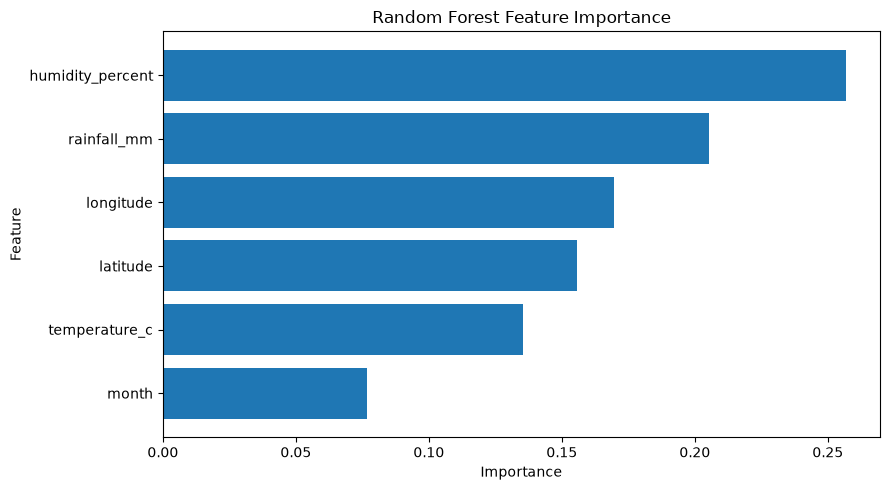

In [62]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

# Load final model dataset
df = pd.read_csv(
    "../processed/landslide_model_data.csv"
)

# Features and target
X = df.drop(columns=["landslide_risk"])
y = df["landslide_risk"]

# Train Random Forest on complete dataset
rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced"
)

rf.fit(X, y)

# Feature importance
importance = pd.DataFrame({
    "feature": X.columns,
    "importance": rf.feature_importances_
})

importance = importance.sort_values(
    "importance",
    ascending=False
)

print("=" * 60)
print("FEATURE IMPORTANCE")
print("=" * 60)

print(importance)

# Plot
plt.figure(figsize=(9, 5))

plt.barh(
    importance["feature"],
    importance["importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [64]:
# Show variables currently available in the notebook
%whos

Variable                     Type                          Data/Info
--------------------------------------------------------------------
GradientBoostingClassifier   ABCMeta                       <class 'sklearn.ensemble.<...>dientBoostingClassifier'>
LAT_MAX                      float64                       28.9986
LAT_MIN                      float64                       22.479
LON_MAX                      float64                       96.9262
LON_MIN                      float64                       88.2426
LogisticRegression           type                          <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
MIN_DISTANCE                 float                         0.1
Pipeline                     ABCMeta                       <class 'sklearn.pipeline.Pipeline'>
RandomForestClassifier       ABCMeta                       <class 'sklearn.ensemble.<...>.RandomForestClassifier'>
StandardScaler               type                          <class 'sklearn.preproces<...>ng.

In [65]:
import os
import joblib

# Create models folder
os.makedirs("../models", exist_ok=True)

# Save the trained Random Forest
joblib.dump(
    rf,
    "../models/random_forest_landslide.pkl"
)

print("✅ Random Forest model saved successfully!")
print("../models/random_forest_landslide.pkl")

✅ Random Forest model saved successfully!
../models/random_forest_landslide.pkl


In [66]:
model_features = [
    "latitude",
    "longitude",
    "rainfall_mm",
    "temperature_c",
    "humidity_percent",
    "month"
]

joblib.dump(
    model_features,
    "../models/landslide_features.pkl"
)

print("✅ Feature list saved!")
print(model_features)

✅ Feature list saved!
['latitude', 'longitude', 'rainfall_mm', 'temperature_c', 'humidity_percent', 'month']


In [67]:
loaded_model = joblib.load(
    "../models/random_forest_landslide.pkl"
)

loaded_features = joblib.load(
    "../models/landslide_features.pkl"
)

print("✅ Model loaded successfully!")
print("Features:", loaded_features)

✅ Model loaded successfully!
Features: ['latitude', 'longitude', 'rainfall_mm', 'temperature_c', 'humidity_percent', 'month']


In [68]:
import pandas as pd

test_data = pd.DataFrame([{
    "latitude": 25.30,
    "longitude": 94.48,
    "rainfall_mm": 42.5,
    "temperature_c": 23.4,
    "humidity_percent": 94.0,
    "month": 8
}])

prediction = loaded_model.predict(test_data)[0]
probability = loaded_model.predict_proba(test_data)[0][1]

print("Prediction:", prediction)
print("Risk Probability:", round(probability * 100, 2), "%")

Prediction: 1
Risk Probability: 97.67 %


# LIVE LANDSLIDE RISK TEST

In [78]:
get_weather(latitude, longitude, date)

(None, None, None)

In [79]:
from datetime import datetime

latitude = 25.30
longitude = 94.48

# Keep this as a datetime object
date = datetime.now()

print("Location:", latitude, longitude)
print("Date:", date)

weather = get_weather(latitude, longitude, date)

print("\nWeather:")
print(weather)

Location: 25.3 94.48
Date: 2026-09-08 01:25:09.192683

Weather:
(None, None, None)


In [80]:
from datetime import datetime, timedelta

latitude = 25.30
longitude = 94.48

# Try yesterday
date = datetime.now() - timedelta(days=1)

print("Location:", latitude, longitude)
print("Date:", date.strftime("%Y-%m-%d"))

weather = get_weather(latitude, longitude, date)

print("\nWeather:")
print(weather)

Location: 25.3 94.48
Date: 2026-09-07

Weather:
(-999.0, -999.0, -999.0)


In [81]:
from datetime import datetime

latitude = 25.30
longitude = 94.48

# Use a recent completed date instead of today
date = datetime(2026, 9, 1)

weather = get_weather(latitude, longitude, date)

print("Location:", latitude, longitude)
print("Date:", date.date())
print("Weather:", weather)

Location: 25.3 94.48
Date: 2026-09-01
Weather: (-999.0, -999.0, -999.0)


In [82]:
def get_weather(lat, lon, date):
    date_str = date.strftime("%Y%m%d")

    url = "https://power.larc.nasa.gov/api/temporal/daily/point"

    params = {
        "parameters": "PRECTOTCORR,T2M,RH2M",
        "community": "AG",
        "longitude": lon,
        "latitude": lat,
        "start": date_str,
        "end": date_str,
        "format": "JSON"
    }

    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()

    data = response.json()["properties"]["parameter"]

    rainfall = data["PRECTOTCORR"].get(date_str, -999)
    temperature = data["T2M"].get(date_str, -999)
    humidity = data["RH2M"].get(date_str, -999)

    # Check for missing NASA values
    if -999 in [rainfall, temperature, humidity]:
        return None

    return rainfall, temperature, humidity

In [83]:
from datetime import datetime

latitude = 25.30
longitude = 94.48
date = datetime(2026, 9, 1)

weather = get_weather(latitude, longitude, date)

print("Location:", latitude, longitude)
print("Date:", date.date())
print("Weather:", weather)

Location: 25.3 94.48
Date: 2026-09-01
Weather: None


In [84]:
from datetime import datetime

latitude = 25.30
longitude = 94.48
date = datetime(2010, 7, 29)

weather = get_weather(latitude, longitude, date)

print("Location:", latitude, longitude)
print("Date:", date.date())
print("Weather:", weather)

Location: 25.3 94.48
Date: 2010-07-29
Weather: (17.06, 21.56, 89.66)


In [85]:
import pandas as pd
import joblib

# --------------------------------------------------
# LIVE LANDSLIDE RISK TEST
# --------------------------------------------------

latitude = 25.30
longitude = 94.48

# Use a date for which weather data is available
date = datetime(2010, 7, 29)

# 1. Get weather
weather = get_weather(latitude, longitude, date)

if weather is None:
    print("❌ Weather data unavailable.")
else:

    rainfall, temperature, humidity = weather

    # 2. Create model input
    live_data = pd.DataFrame([{
        "latitude": latitude,
        "longitude": longitude,
        "rainfall_mm": rainfall,
        "temperature_c": temperature,
        "humidity_percent": humidity,
        "month": date.month
    }])

    print("==============================================")
    print("LIVE DATA")
    print("==============================================")
    print(live_data)

    # 3. Load trained Random Forest
    rf_model = joblib.load(
        "../models/random_forest_landslide.pkl"
    )

    # 4. Prediction
    prediction = rf_model.predict(live_data)[0]

    probability = rf_model.predict_proba(live_data)[0][1]

    # 5. Display result
    print("\n==============================================")
    print("LANDSLIDE RISK PREDICTION")
    print("==============================================")

    print("Location:", latitude, longitude)
    print("Date:", date.date())
    print("Rainfall:", rainfall, "mm")
    print("Temperature:", temperature, "°C")
    print("Humidity:", humidity, "%")

    print("\nPrediction:", prediction)
    print("Probability:", round(probability * 100, 2), "%")

    if prediction == 1:
        print("Risk Level: HIGH")
    else:
        print("Risk Level: LOW")

    print("==============================================")

LIVE DATA
   latitude  longitude  rainfall_mm  temperature_c  humidity_percent  month
0      25.3      94.48        17.06          21.56             89.66      7

LANDSLIDE RISK PREDICTION
Location: 25.3 94.48
Date: 2010-07-29
Rainfall: 17.06 mm
Temperature: 21.56 °C
Humidity: 89.66 %

Prediction: 1
Probability: 98.67 %
Risk Level: HIGH


In [1]:
import joblib

model = joblib.load("models/random_forest_landslide.pkl")
features = joblib.load("models/landslide_features.pkl")

print("MODEL:")
print(model)

print("\nFEATURES:")
print(features)

FileNotFoundError: [Errno 2] No such file or directory: 'models/random_forest_landslide.pkl'

In [2]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles/folders here:")
print(os.listdir())

Current folder:
c:\Users\ARYAN-PC\Desktop\rugvedi\landslide-risk-prediction\notebooks

Files/folders here:
['landslide_ml.ipynb']


In [3]:
import os

for root, dirs, files in os.walk(r"C:\Users\ARYAN-PC\Desktop\rugvedi\landslide-risk-prediction"):
    for file in files:
        if file.endswith(".pkl"):
            print(os.path.join(root, file))

C:\Users\ARYAN-PC\Desktop\rugvedi\landslide-risk-prediction\.venv\Lib\site-packages\joblib\test\data\joblib_0.10.0_pickle_py27_np17.pkl
C:\Users\ARYAN-PC\Desktop\rugvedi\landslide-risk-prediction\.venv\Lib\site-packages\joblib\test\data\joblib_0.10.0_pickle_py33_np18.pkl
C:\Users\ARYAN-PC\Desktop\rugvedi\landslide-risk-prediction\.venv\Lib\site-packages\joblib\test\data\joblib_0.10.0_pickle_py34_np19.pkl
C:\Users\ARYAN-PC\Desktop\rugvedi\landslide-risk-prediction\.venv\Lib\site-packages\joblib\test\data\joblib_0.10.0_pickle_py35_np19.pkl
C:\Users\ARYAN-PC\Desktop\rugvedi\landslide-risk-prediction\.venv\Lib\site-packages\joblib\test\data\joblib_0.11.0_pickle_py36_np111.pkl
C:\Users\ARYAN-PC\Desktop\rugvedi\landslide-risk-prediction\.venv\Lib\site-packages\joblib\test\data\joblib_0.9.2_pickle_py27_np16.pkl
C:\Users\ARYAN-PC\Desktop\rugvedi\landslide-risk-prediction\.venv\Lib\site-packages\joblib\test\data\joblib_0.9.2_pickle_py27_np17.pkl
C:\Users\ARYAN-PC\Desktop\rugvedi\landslide-risk-

In [4]:
import joblib

model_path = r"C:\Users\ARYAN-PC\Desktop\rugvedi\landslide-risk-prediction\models\random_forest_landslide.pkl"
features_path = r"C:\Users\ARYAN-PC\Desktop\rugvedi\landslide-risk-prediction\models\landslide_features.pkl"

model = joblib.load(model_path)
features = joblib.load(features_path)

print("Model loaded successfully!")
print("\nModel:")
print(model)

print("\nFeatures:")
print(features)

Model loaded successfully!

Model:
RandomForestClassifier(class_weight='balanced', n_estimators=300,
                       random_state=42)

Features:
['latitude', 'longitude', 'rainfall_mm', 'temperature_c', 'humidity_percent', 'month']


In [6]:
print("Features used by the model:")
print(model.feature_names_in_)

print("\nFeature importance:")
for feature, importance in zip(
    model.feature_names_in_,
    model.feature_importances_
):
    print(f"{feature:20s} : {importance:.4f}")

Features used by the model:
['latitude' 'longitude' 'rainfall_mm' 'temperature_c' 'humidity_percent'
 'month']

Feature importance:
latitude             : 0.1558
longitude            : 0.1696
rainfall_mm          : 0.2054
temperature_c        : 0.1355
humidity_percent     : 0.2568
month                : 0.0769


In [7]:
import os

project = r"C:\Users\ARYAN-PC\Desktop\rugvedi\landslide-risk-prediction"

for root, dirs, files in os.walk(project):
    for file in files:
        if file.endswith((".csv", ".xlsx", ".parquet")):
            print(os.path.join(root, file))

C:\Users\ARYAN-PC\Desktop\rugvedi\landslide-risk-prediction\.venv\Lib\site-packages\matplotlib\mpl-data\sample_data\data_x_x2_x3.csv
C:\Users\ARYAN-PC\Desktop\rugvedi\landslide-risk-prediction\.venv\Lib\site-packages\matplotlib\mpl-data\sample_data\msft.csv
C:\Users\ARYAN-PC\Desktop\rugvedi\landslide-risk-prediction\.venv\Lib\site-packages\matplotlib\mpl-data\sample_data\Stocks.csv
C:\Users\ARYAN-PC\Desktop\rugvedi\landslide-risk-prediction\.venv\Lib\site-packages\numpy\random\tests\data\mt19937-testset-1.csv
C:\Users\ARYAN-PC\Desktop\rugvedi\landslide-risk-prediction\.venv\Lib\site-packages\numpy\random\tests\data\mt19937-testset-2.csv
C:\Users\ARYAN-PC\Desktop\rugvedi\landslide-risk-prediction\.venv\Lib\site-packages\numpy\random\tests\data\pcg64-testset-1.csv
C:\Users\ARYAN-PC\Desktop\rugvedi\landslide-risk-prediction\.venv\Lib\site-packages\numpy\random\tests\data\pcg64-testset-2.csv
C:\Users\ARYAN-PC\Desktop\rugvedi\landslide-risk-prediction\.venv\Lib\site-packages\numpy\random\te

In [8]:
import pandas as pd

path = r"C:\Users\ARYAN-PC\Desktop\rugvedi\landslide-risk-prediction\processed\landslide_model_data.csv"

df = pd.read_csv(path)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Shape: (502, 7)

Columns:
['latitude', 'longitude', 'rainfall_mm', 'temperature_c', 'humidity_percent', 'month', 'landslide_risk']

First 5 rows:


,latitude,longitude,rainfall_mm,temperature_c,humidity_percent,month,landslide_risk
0,24.607915,93.196107,0.42,25.53,52.87,3,0
1,25.011800,94.313600,11.95,24.11,88.73,7,1
2,23.965046,91.951433,0.03,28.00,87.26,8,0
3,27.322000,88.608700,0.26,9.67,79.74,4,1
4,26.196300,91.807400,7.89,28.30,86.26,7,1


In [9]:
print("\nRainfall statistics:")
print(df["rainfall_mm"].describe())

print("\nWeather features:")
display(
    df[
        [
            "latitude",
            "longitude",
            "rainfall_mm",
            "temperature_c",
            "humidity_percent",
            "month"
        ]
    ].head(10)
)


Rainfall statistics:
count    502.000000
mean      12.445378
std       21.822431
min        0.000000
25%        0.265000
50%        4.640000
75%       13.245000
max      126.760000
Name: rainfall_mm, dtype: float64

Weather features:


,latitude,longitude,rainfall_mm,temperature_c,humidity_percent,month
0,24.607915,93.196107,0.42,25.53,52.87,3
1,25.011800,94.313600,11.95,24.11,88.73,7
2,23.965046,91.951433,0.03,28.00,87.26,8
3,27.322000,88.608700,0.26,9.67,79.74,4
4,26.196300,91.807400,7.89,28.30,86.26,7
5,23.201964,92.057622,2.70,27.18,87.32,9
6,27.083417,88.949000,0.00,9.44,39.66,2
7,24.984900,92.841100,5.60,25.23,77.80,5
8,25.480000,94.138300,18.30,20.32,89.44,7
9,24.089600,91.466300,45.59,28.33,86.41,5


In [10]:
import pandas as pd

base = r"C:\Users\ARYAN-PC\Desktop\rugvedi\landslide-risk-prediction\processed"

files = [
    "landslide_weather.csv",
    "northeast_historical_weather.csv",
    "northeast_rainfall_locations.csv",
    "landslide_negative_weather.csv"
]

for file in files:
    path = base + "\\" + file
    temp = pd.read_csv(path)

    print("\n" + "="*70)
    print(file)
    print("Shape:", temp.shape)
    print("Columns:", temp.columns.tolist())
    print(temp.head(3).to_string(index=False))


landslide_weather.csv
Shape: (251, 6)
Columns: ['latitude', 'longitude', 'event_date', 'rainfall_mm', 'temperature_c', 'humidity_percent']
 latitude  longitude          event_date  rainfall_mm  temperature_c  humidity_percent
25.309863  94.482147 2010-07-29 23:00:00        17.06          21.56             89.66
24.141900  94.107800 2015-08-01 00:00:00         2.09          24.29             91.61
25.521500  93.164500 2009-08-20 00:00:00        12.55          24.40             91.65

northeast_historical_weather.csv
Shape: (251, 6)
Columns: ['latitude', 'longitude', 'event_date', 'rainfall_mm', 'temperature_c', 'humidity_percent']
 latitude  longitude          event_date  rainfall_mm  temperature_c  humidity_percent
25.309863  94.482147 2010-07-29 23:00:00        17.06          21.56             89.66
24.141900  94.107800 2015-08-01 00:00:00         2.09          24.29             91.61
25.521500  93.164500 2009-08-20 00:00:00        12.55          24.40             91.65

northeast_ra